# Healthcare Expenditure and Life Expectancy Across Countries: An Extended Panel Data Analysis

**Course:** Data Science — Final Project
**Data:** World Bank World Development Indicators (WDI) API; health-expenditure series originate from the WHO Global Health Expenditure Database
**Period / sample:** 2000–2023, 186 countries (4,404 country-years in the analytic sample)

---

## Project overview

**Research question.** How is healthcare expenditure associated with life expectancy across countries? Has this relationship changed over time? Does it remain consistent after accounting for economic development (GDP per capita), financing structure (out-of-pocket share), nonlinearity and alternative model specifications?

**Why it matters.** Countries that spend more on health do not always live proportionally longer; the United States versus France is a well-known example. Updated evidence helps researchers and policymakers judge whether more spending is consistently associated with longer lives.

**Approach (following the approved proposal, FPb):**

| # | Section | What is done |
|---|---|---|
| 1 | Setup | Libraries, paths, indicator definitions, plotting style |
| 2 | Data collection | Download 10 indicators and country metadata from the World Bank API (cached locally) |
| 3 | Preprocessing | Remove aggregates, merge into a country-year panel, uniqueness and validity checks (failed records excluded), missing-value and outlier documentation, feature engineering (logs, periods), analytic sample |
| 4 | Exploratory data analysis | Descriptive statistics, distributions, trends, scatterplots, boxplots, correlations, choropleth maps, France vs US with context indicators |
| 5 | Panel regression (main method) | Pooled OLS → country fixed effects → two-way fixed effects → + GDP → + out-of-pocket share → nonlinear model, with a flexible check; Hausman test |
| 6 | Robustness & heterogeneity | Alternative spending measures (incl. constant prices), balanced panel, COVID exclusion, outliers, lags, 5-year averages, long differences, between estimator, income groups, regions, periods (incl. why the link weakened), other outcomes |
| 7 | Statistical inference | Permutation tests and bootstrap confidence intervals (high vs low out-of-pocket burden), sensitivity to single countries, country-cluster bootstrap |
| 8 | Country performance | Who does better or worse than expected for their spending level; how model-dependent the US gap is |
| 9 | Interactive dashboard | A standalone HTML explorer (countries, regions, indicators, years) |
| 10 | Summary and conclusions | Supported findings, model-dependent results, hypotheses, policy implications, future research, limitations |

**Interpretation note.** All results are *statistical associations*, not proof that spending causes longer life.

## 1. Setup

All code runs from the repository root. The packages are listed in `requirements.txt`. Raw API responses are cached in `data/raw/`, so the notebook can be re-run offline; set `REFRESH = True` to download fresh data.

In [1]:
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import requests
import matplotlib as mpl
import matplotlib.pyplot as plt
import plotly.express as px
import statsmodels.formula.api as smf
from scipy import stats
from statsmodels.nonparametric.smoothers_lowess import lowess
from linearmodels.panel import PanelOLS, PooledOLS, RandomEffects
from IPython.display import Image, Markdown, display

warnings.filterwarnings("ignore")   # silence harmless numpy/linearmodels runtime warnings
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

REFRESH = False                      # True = re-download data from the World Bank API
SEED = 42
rng = np.random.default_rng(SEED)

# ---- Paths ----
ROOT = Path.cwd()
RAW_DIR, PROCESSED_DIR = ROOT / "data" / "raw", ROOT / "data" / "processed"
FIG_DIR, TABLE_DIR, MAP_DIR = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables", ROOT / "outputs" / "maps"
for d in (RAW_DIR, PROCESSED_DIR, FIG_DIR, TABLE_DIR, MAP_DIR):
    d.mkdir(parents=True, exist_ok=True)

### Indicators

The five **core indicators** come from Section 5 of the proposal. Five **secondary indicators** are added: current-US$ spending, for comparison with earlier studies, and financing shares and mortality outcomes, from the proposal's extensions. Section 4.9 also uses five **context indicators** for the France–US comparison only; they are not used in any model.

In [2]:
CORE_INDICATORS = {
    "SH.XPD.CHEX.PP.CD": "che_pc_ppp",    # Current health expenditure per capita, PPP (current intl $)  -> main spending measure
    "SH.XPD.CHEX.GD.ZS": "che_pct_gdp",   # Current health expenditure, % of GDP                          -> alternative spending measure
    "SH.XPD.OOPC.CH.ZS": "oop_pct_che",   # Out-of-pocket expenditure, % of current health expenditure    -> financial burden
    "SP.DYN.LE00.IN":    "life_exp",      # Life expectancy at birth (years)                              -> outcome
    "NY.GDP.PCAP.PP.KD": "gdp_pc_ppp",    # GDP per capita, PPP (constant 2021 intl $)                    -> economic control
}
EXTRA_INDICATORS = {
    "SH.XPD.CHEX.PC.CD": "che_pc_usd",    # Health expenditure per capita, current US$ (comparison with older studies)
    "SH.XPD.GHED.CH.ZS": "gov_pct_che",   # Government health expenditure, % of CHE
    "SH.XPD.PVTD.CH.ZS": "pvt_pct_che",   # Private health expenditure, % of CHE
    "SH.DYN.MORT":       "u5_mort",       # Under-5 mortality (per 1,000 live births)
    "SH.STA.MMRT":       "mat_mort",      # Maternal mortality ratio (per 100,000 live births)
}
INDICATORS = {**CORE_INDICATORS, **EXTRA_INDICATORS}
CORE = list(CORE_INDICATORS.values())

LABELS = {
    "che_pc_ppp": "Health expenditure per capita, PPP (current intl $)",
    "che_pct_gdp": "Health expenditure (% of GDP)",
    "oop_pct_che": "Out-of-pocket expenditure (% of CHE)",
    "life_exp": "Life expectancy at birth (years)",
    "gdp_pc_ppp": "GDP per capita, PPP (constant 2021 intl $)",
    "che_pc_usd": "Health expenditure per capita (current US$)",
    "gov_pct_che": "Government health expenditure (% of CHE)",
    "pvt_pct_che": "Private health expenditure (% of CHE)",
    "u5_mort": "Under-5 mortality (per 1,000 live births)",
    "mat_mort": "Maternal mortality (per 100,000 live births)",
}
INCOME_ORDER = ["Low income", "Lower middle income", "Upper middle income", "High income"]
HIGHLIGHT = {"FRA": "France", "USA": "United States"}
pd.DataFrame({"code": INDICATORS.keys(), "variable": INDICATORS.values(),
              "description": [LABELS[v] for v in INDICATORS.values()],
              "role": ["core"] * 5 + ["secondary"] * 5})

,code,variable,description,role
0,SH.XPD.CHEX.PP.CD,che_pc_ppp,"Health expenditure per capita, PPP (current in...",core
1,SH.XPD.CHEX.GD.ZS,che_pct_gdp,Health expenditure (% of GDP),core
2,SH.XPD.OOPC.CH.ZS,oop_pct_che,Out-of-pocket expenditure (% of CHE),core
3,SP.DYN.LE00.IN,life_exp,Life expectancy at birth (years),core
4,NY.GDP.PCAP.PP.KD,gdp_pc_ppp,"GDP per capita, PPP (constant 2021 intl $)",core
5,SH.XPD.CHEX.PC.CD,che_pc_usd,Health expenditure per capita (current US$),secondary
6,SH.XPD.GHED.CH.ZS,gov_pct_che,Government health expenditure (% of CHE),secondary
7,SH.XPD.PVTD.CH.ZS,pvt_pct_che,Private health expenditure (% of CHE),secondary
8,SH.DYN.MORT,u5_mort,"Under-5 mortality (per 1,000 live births)",secondary
9,SH.STA.MMRT,mat_mort,"Maternal mortality (per 100,000 live births)",secondary


### Plotting style

All charts share one palette. Income groups are **ordered** categories, so they use a single blue ramp from light (low income) to dark (high income). France is blue and the United States orange.

In [3]:
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INCOME_COLORS = dict(zip(INCOME_ORDER, ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]))
COUNTRY_COLORS = {"FRA": SERIES[0], "USA": SERIES[1]}
SEQ_CMAP = mpl.colors.LinearSegmentedColormap.from_list("seq", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
DIV_CMAP = mpl.colors.LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#f0efec", "#ec9a99", "#c0302f"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.labelsize": 9, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelsize": 8, "ytick.labelsize": 8,
    "legend.frameon": False, "legend.fontsize": 8, "lines.linewidth": 2, "font.size": 9,
    "figure.dpi": 100, "savefig.dpi": 160, "savefig.bbox": "tight",
})

def save(fig, name):
    # Save a figure to outputs/figures and show it inline
    fig.savefig(FIG_DIR / name)
    plt.show()

## 2. Data collection

Data are retrieved from the **World Bank API** (`api.worldbank.org/v2`), the common access point named in the proposal.

- For each indicator, all economies are requested for 2000–2025, at up to 20,000 rows per page, with automatic paging and retries.
- Country metadata (region, income group) come from a separate endpoint.
- Every raw response is saved unchanged as JSON in `data/raw/` for reproducibility.
- The five context indicators for Section 4.9 are downloaded the same way when that section runs (one of them, the coverage index, comes from the WHO Global Health Observatory API).

In [4]:
API = "https://api.worldbank.org/v2"
START_YEAR, END_YEAR = 2000, 2025

def fetch_json(url, params, retries=4):
    # GET a JSON page from the API with exponential back-off on failure
    for attempt in range(retries):
        try:
            r = requests.get(url, params=params, timeout=60)
            r.raise_for_status()
            return r.json()
        except (requests.RequestException, ValueError) as e:
            print(f"  request failed ({e}); retrying in {2 ** attempt}s")
            time.sleep(2 ** attempt)
    raise RuntimeError(f"Failed to fetch {url}")

def fetch_all_pages(url, params):
    # Collect every page of an API result
    params = {**params, "format": "json", "per_page": 20000, "page": 1}
    first = fetch_json(url, params)
    meta, rows = first[0], first[1] or []
    for page in range(2, meta["pages"] + 1):
        params["page"] = page
        rows.extend(fetch_json(url, params)[1] or [])
    return meta, rows

def collect_indicator(code):
    # Download one indicator (or load the cached copy)
    path = RAW_DIR / f"{code}.json"
    if path.exists() and not REFRESH:
        return json.loads(path.read_text())
    meta, rows = fetch_all_pages(f"{API}/country/all/indicator/{code}", {"date": f"{START_YEAR}:{END_YEAR}"})
    payload = {"meta": meta, "rows": rows}
    path.write_text(json.dumps(payload))
    return payload

def collect_countries():
    # Download country metadata: region and income group (or load the cached copy)
    path = RAW_DIR / "countries.json"
    if path.exists() and not REFRESH:
        return json.loads(path.read_text())
    _, rows = fetch_all_pages(f"{API}/country", {})
    path.write_text(json.dumps(rows))
    return rows

In [5]:
# ---- Download / load all indicators into one long table: iso3 | year | indicator | value ----
frames, summary = [], []
for code, name in INDICATORS.items():
    payload = collect_indicator(code)
    df_i = pd.DataFrame({"iso3": r["countryiso3code"], "year": r["date"], "indicator": name, "value": r["value"]}
                        for r in payload["rows"])
    frames.append(df_i)
    summary.append({"code": code, "variable": name, "rows": len(df_i), "non_null": df_i["value"].notna().sum(),
                    "last_updated": payload["meta"].get("lastupdated")})
long = pd.concat(frames, ignore_index=True)
long.to_csv(RAW_DIR / "wdi_long.csv", index=False)

# ---- Country metadata ----
meta = pd.DataFrame({"iso3": c["id"], "country": c["name"], "region": c["region"]["value"],
                     "income_group": c["incomeLevel"]["value"]} for c in collect_countries())
meta.to_csv(RAW_DIR / "country_meta.csv", index=False)

print(f"Long table: {len(long):,} rows | country metadata: {len(meta)} entries "
      f"({(meta.region == 'Aggregates').sum()} are regional/income aggregates)")
pd.DataFrame(summary)

Long table: 69,160 rows | country metadata: 296 entries (79 are regional/income aggregates)


,code,variable,rows,non_null,last_updated
0,SH.XPD.CHEX.PP.CD,che_pc_ppp,6916,5715,2026-10-08
1,SH.XPD.CHEX.GD.ZS,che_pct_gdp,6916,5716,2026-10-08
2,SH.XPD.OOPC.CH.ZS,oop_pct_che,6916,5716,2026-10-08
3,SP.DYN.LE00.IN,life_exp,6916,6625,2026-10-08
4,NY.GDP.PCAP.PP.KD,gdp_pc_ppp,6916,6349,2026-10-08
5,SH.XPD.CHEX.PC.CD,che_pc_usd,6916,5713,2026-10-08
6,SH.XPD.GHED.CH.ZS,gov_pct_che,6916,5699,2026-10-08
7,SH.XPD.PVTD.CH.ZS,pvt_pct_che,6916,5699,2026-10-08
8,SH.DYN.MORT,u5_mort,6916,6100,2026-10-08
9,SH.STA.MMRT,mat_mort,6916,5808,2026-10-08


In [6]:
long.head()

,iso3,year,indicator,value
0,AFE,2025,che_pc_ppp,NaN
1,AFE,2024,che_pc_ppp,NaN
2,AFE,2023,che_pc_ppp,235.895
3,AFE,2022,che_pc_ppp,228.535
4,AFE,2021,che_pc_ppp,220.535


## 3. Data preprocessing

These steps follow the methodology in the proposal:

| # | What we do | Why it's needed |
|---|---|---|
| 1 | Keep only real countries. Remove groups such as "World", "Europe" or "High income". | Groups are averages of many countries, so keeping them would count the same countries twice. |
| 2 | Make sure years and values are stored as numbers, and check for duplicate records. | Calculations need numbers, not text. A duplicate would count the same data twice. |
| 3 | Reshape the data to one row per country per year, and add each country's region and income group. | The models need this layout, and the groups let us compare regions and income levels. |
| 4 | Choose which years to study, based on how many countries have data. | Years with very few countries can't support a fair global comparison. |
| 5 | Check for values outside a valid range, such as a percentage above 100 or a life expectancy below 20. Rows that fail are left out of the models. | Values outside the valid range would distort the results. |
| 6 | Record which values are missing. Never fill them with zero or a guess. | A zero would wrongly mean "spent nothing on health", and a guess would be invented data. |
| 7 | Find unusual values and flag them, but keep them. | Many are real events such as wars or disasters. Flagging them lets us test later whether they change the results. |
| 8 | Add new columns: logs of spending and GDP, time periods, and a COVID marker. | Logs handle very uneven values, periods show change over time, and the marker lets us test results without 2020–21. |
| 9 | Build the final dataset (complete rows that passed the checks), plus a smaller one with only the countries that have data for all 24 years. | The models need complete rows. The smaller dataset checks that results aren't caused by countries entering or leaving the data. |

### 3.1 Remove aggregates, standardise types, check uniqueness

In [7]:
economies = meta[meta["region"] != "Aggregates"].copy()
economies["country"] = economies["country"].replace({"Naoero": "Nauru"})   # the API labels Nauru by its local name
long = long[long["iso3"].isin(economies["iso3"])].copy()

long["year"] = pd.to_numeric(long["year"], errors="coerce").astype(int)
long["value"] = pd.to_numeric(long["value"], errors="coerce")
long["iso3"] = long["iso3"].str.strip().str.upper()

dups = long.duplicated(["iso3", "year", "indicator"]).sum()
print(f"Economies kept: {economies.shape[0]} | rows: {len(long):,} | duplicate country-year-indicator records: {dups}")

Economies kept: 217 | rows: 56,420 | duplicate country-year-indicator records: 0


### 3.2 Pivot to a country-year panel

In [8]:
panel = (long.pivot(index=["iso3", "year"], columns="indicator", values="value")
             .reset_index().rename_axis(columns=None)
             .merge(economies, on="iso3", how="left"))
assert not panel.duplicated(["iso3", "year"]).any(), "country-year keys are not unique"
print(f"Panel: {panel.shape[0]:,} country-years x {panel.shape[1]} columns — unique (iso3, year) keys verified")
panel.dtypes.to_frame("dtype").T

Panel: 5,642 country-years x 15 columns — unique (iso3, year) keys verified


,iso3,year,che_pc_ppp,che_pc_usd,che_pct_gdp,gdp_pc_ppp,gov_pct_che,life_exp,mat_mort,oop_pct_che,pvt_pct_che,u5_mort,country,region,income_group
dtype,object,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,object,object,object


### 3.3 Study window

The proposal planned "the longest common period with sufficient coverage, expected to begin around 2000". The coverage table shows that health expenditure is available for about 184–193 countries every year up to **2023**, but for only 22 countries in 2024. The study window is therefore **2000–2023**.

In [9]:
coverage = panel.groupby("year")[list(INDICATORS.values())].count()
coverage.to_csv(TABLE_DIR / "preprocessing_coverage_by_year.csv")
display(coverage.loc[[2000, 2005, 2010, 2015, 2020, 2021, 2022, 2023, 2024, 2025], CORE])

STUDY_START, STUDY_END = 2000, 2023
panel = panel[panel["year"].between(STUDY_START, STUDY_END)].copy()
panel["income_group"] = panel["income_group"].replace({"Not classified": np.nan})
print(f"Study window {STUDY_START}-{STUDY_END}: {len(panel):,} country-years ({panel.iso3.nunique()} economies x 24 years)")

,che_pc_ppp,che_pct_gdp,oop_pct_che,life_exp,gdp_pc_ppp
year,,,,,
2000,184,184,184,217,192
2005,187,187,187,217,193
2010,188,188,188,217,198
2015,191,191,191,217,199
2020,193,193,193,217,199
2021,193,193,193,217,199
2022,192,192,192,217,199
2023,192,192,192,217,197
2024,22,22,22,217,195


Study window 2000-2023: 5,208 country-years (217 economies x 24 years)


### 3.4 Validity and consistency checks

Each check flags suspicious records; nothing is silently fixed. The out-of-pocket share must not exceed the private share, because out-of-pocket payments are part of private spending. The government and private shares together should not exceed 100%.

In [10]:
checks = {
    "life_exp outside [20, 95]": ~panel["life_exp"].between(20, 95) & panel["life_exp"].notna(),
    "percentage outside [0, 100]": panel[["oop_pct_che", "che_pct_gdp", "gov_pct_che", "pvt_pct_che"]]
                                     .apply(lambda s: ~s.between(0, 100) & s.notna()).any(axis=1),
    "non-positive spending or GDP": panel[["che_pc_ppp", "gdp_pc_ppp", "che_pc_usd"]]
                                     .apply(lambda s: (s <= 0) & s.notna()).any(axis=1),
    "gov% + private% > 105": (panel["gov_pct_che"] + panel["pvt_pct_che"]) > 105,
    "OOP% > private% + 1": panel["oop_pct_che"] > panel["pvt_pct_che"] + 1,
}
panel["flag_invalid"] = np.column_stack([v.fillna(False) for v in checks.values()]).any(axis=1)
check_tbl = pd.DataFrame({"check": list(checks), "n_flagged": [int(v.sum()) for v in checks.values()]})
check_tbl.to_csv(TABLE_DIR / "preprocessing_validity_checks.csv", index=False)
display(check_tbl)
panel.loc[panel.flag_invalid, ["country", "year", "life_exp"]]

,check,n_flagged
0,"life_exp outside [20, 95]",2
1,"percentage outside [0, 100]",0
2,non-positive spending or GDP,0
3,gov% + private% > 105,0
4,OOP% > private% + 1,0


,country,year,life_exp
815,Central African Republic,2009,14.665
828,Central African Republic,2022,18.818


Only two records fail: the Central African Republic's estimated life expectancy in 2009 (14.7 years) and 2022 (18.8 years), both crisis years. Values this low can appear in UN estimates for years with mass deaths, but they fall outside the valid range we set in advance (20–95 years). We apply the rule consistently: the two records stay in `panel_full.csv` with `flag_invalid = True`, and they are **excluded from the analytic sample** (Section 3.8).

### 3.5 Missing values

As the proposal states, missing values are **not replaced with zero**: a zero would wrongly mean "spent nothing on health". They are documented instead.

In [11]:
ALL_VARS = list(INDICATORS.values())
miss = pd.DataFrame({"missing": panel[ALL_VARS].isna().sum(),
                     "pct_missing": (panel[ALL_VARS].isna().mean() * 100).round(1)}).sort_values("missing", ascending=False)
miss.to_csv(TABLE_DIR / "preprocessing_missing_by_variable.csv")
miss

,missing,pct_missing
che_pc_usd,671,12.900
che_pc_ppp,669,12.800
che_pct_gdp,668,12.800
oop_pct_che,668,12.800
gov_pct_che,668,12.800
pvt_pct_che,668,12.800
mat_mort,552,10.600
u5_mort,504,9.700
gdp_pc_ppp,487,9.400
life_exp,0,0.000


In [12]:
n_years = STUDY_END - STUDY_START + 1
missing_years = panel.groupby("country")["che_pc_ppp"].apply(lambda s: s.isna().sum())
never = missing_years[missing_years == n_years].index.tolist()
partial = missing_years[(missing_years > 0) & (missing_years < n_years)].sort_values(ascending=False)

print(f"Economies with NO health-expenditure data ({len(never)}):\n  " + ", ".join(never))
print(f"\nEconomies with partial gaps in health expenditure (years missing out of {n_years}):")
print(partial.to_string())
(panel.groupby(["iso3", "country"])[CORE].apply(lambda d: d.isna().sum()).reset_index()
      .to_csv(TABLE_DIR / "preprocessing_missing_by_country.csv", index=False))

Economies with NO health-expenditure data (24):
  American Samoa, Aruba, Bermuda, British Virgin Islands, Cayman Islands, Channel Islands, Curacao, Faroe Islands, French Polynesia, Gibraltar, Greenland, Guam, Hong Kong SAR, China, Isle of Man, Korea, Dem. People's Rep., Kosovo, Macao SAR, China, New Caledonia, Northern Mariana Islands, Puerto Rico (US), Sint Maarten (Dutch part), St. Martin (French part), Turks and Caicos Islands, Virgin Islands (U.S.)

Economies with partial gaps in health expenditure (years missing out of 24):
country
Venezuela, RB         19
South Sudan           17
Liechtenstein         13
Somalia, Fed. Rep.    13
Montenegro            11
Zimbabwe              10
Iraq                   3
Timor-Leste            3
Afghanistan            2
Ukraine                2


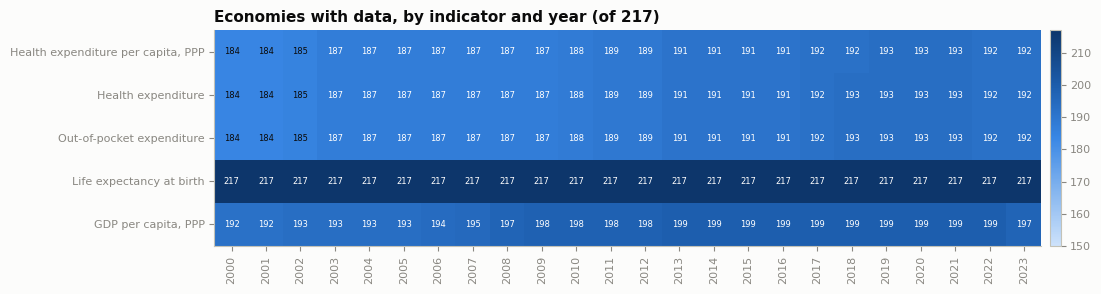

In [13]:
# Visual: how many economies have each core indicator, by year
cov = pd.concat([coverage.loc[STUDY_START:STUDY_END, CORE]]).T
fig, ax = plt.subplots(figsize=(11, 2.8))
im = ax.imshow(cov.values, aspect="auto", cmap=SEQ_CMAP, vmin=150, vmax=217)
ax.set_yticks(range(len(CORE)), [LABELS[c].split(" (")[0] for c in CORE])
ax.set_xticks(range(len(cov.columns)), cov.columns, rotation=90)
ax.grid(False)
for (i, j), v in np.ndenumerate(cov.values):
    ax.text(j, i, v, ha="center", va="center", fontsize=6, color="white" if v > 185 else INK)
ax.set_title("Economies with data, by indicator and year (of 217)", loc="left")
fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01)
save(fig, "fig01_coverage.png")

Each cell shows how many of the 217 economies have data for one indicator (row) in one year (column); darker means more. Life expectancy is complete (217 every year), the three health-expenditure indicators cover 184–193 economies, and GDP covers 192–199.

Missing data come mainly from two sources:

- **Small territories that never report health accounts**, such as Aruba, Bermuda and Guam.
- **Countries with conflict, crisis or late independence**, such as Venezuela, South Sudan (independent in 2011), Somalia and Montenegro (independent in 2006).

Coverage is stable over time, so the missing values do not create a time trend.

### 3.6 Feature engineering

- **Logarithms** of spending and GDP. Both are strongly right-skewed (Section 4.2), and the spending–life expectancy relationship is close to linear in logs. A coefficient on log spending then means: a 10% increase in spending ↔ coefficient × ln(1.1) ≈ 0.095 × coefficient years.
- **Periods:** 2000–2007, 2008–2015 and 2016–2023, for testing whether the relationship changed over time.
- **COVID indicator** for 2020–2021, when life expectancy fell sharply worldwide.
- **A note on prices.** Health spending is in *current* international dollars, which include inflation, while GDP is in *constant* 2021 dollars. Inflation of the international dollar affects all countries in a given year in a broadly similar way, so the year fixed effects absorb most of it in the linear two-way models (3)–(5), though not all of it, because the current-price and constant-price series use different country-specific adjustments (the estimate moves from 0.54 to 0.71 when constant prices are used). It can matter for the pooled and country-only models and for the nonlinear model, so Section 6 repeats them with spending rebuilt in constant 2021 dollars.

In [14]:
for v in ["che_pc_ppp", "gdp_pc_ppp", "che_pc_usd", "u5_mort", "mat_mort"]:
    panel[f"log_{v}"] = np.log(panel[v])
panel["period"] = pd.cut(panel["year"], [1999, 2007, 2015, 2023], labels=["2000-2007", "2008-2015", "2016-2023"])
panel["covid"] = panel["year"].isin([2020, 2021])
panel[["iso3", "year", "che_pc_ppp", "log_che_pc_ppp", "gdp_pc_ppp", "log_gdp_pc_ppp", "period", "covid"]].sample(5, random_state=1)

,iso3,year,che_pc_ppp,log_che_pc_ppp,gdp_pc_ppp,log_gdp_pc_ppp,period,covid
536,BHS,2016,"1,804.895",7.498,"32,172.337",10.379,2016-2023,False
4399,SEN,2005,86.362,4.459,"3,301.821",8.102,2000-2007,False
5598,ZMB,2008,121.691,4.801,"2,908.144",7.975,2008-2015,False
2097,GUM,2017,NaN,NaN,NaN,NaN,2016-2023,False
5637,ZWE,2021,85.053,4.443,"4,827.110",8.482,2016-2023,True


### 3.7 Outlier investigation

The proposal requires outliers to be "investigated and documented rather than automatically removed". Two kinds are flagged:

- **Cross-sectional outliers:** a country that is very different from other countries in the same year. We use a robust z-score (based on the median and the median absolute deviation, MAD) with |z| > 3.5, a commonly recommended cut-off for this score (Iglewicz & Hoaglin, 1993).
- **Year-on-year jumps:** a country that changes suddenly from one year to the next, with |robust z| > 8. This cut-off is a judgement call. Most yearly changes are tiny, so their MAD is small and a cut-off of 3.5 would flag 818 country-years. A score of 8 corresponds to large shocks, for example a life-expectancy change about 2.3 years away from the typical change of +0.25 years. Such jumps usually signal wars, disasters, COVID-19 or data revisions.

In [15]:
def robust_z(s):
    # Robust z-score based on median and median absolute deviation (insensitive to the outliers themselves)
    med, mad = s.median(), (s - s.median()).abs().median()
    return 0.6745 * (s - med) / mad if mad > 0 else s * 0

out_rows = []
for var in ["log_che_pc_ppp", "oop_pct_che", "che_pct_gdp", "life_exp", "log_gdp_pc_ppp"]:
    z = panel.groupby("year")[var].transform(robust_z)
    for idx in z[z.abs() > 3.5].index:
        r = panel.loc[idx]
        out_rows.append(["cross-sectional", var, r.iso3, r.country, r.year, r[var], z[idx]])

panel = panel.sort_values(["iso3", "year"])
for var in ["log_che_pc_ppp", "oop_pct_che", "life_exp"]:
    diff = panel.groupby("iso3")[var].diff()
    z = robust_z(diff.dropna()).reindex(diff.index)
    for idx in z[z.abs() > 8].index:
        r = panel.loc[idx]
        out_rows.append(["year-on-year jump", var, r.iso3, r.country, r.year, diff[idx], z[idx]])

outliers = pd.DataFrame(out_rows, columns=["type", "variable", "iso3", "country", "year", "value", "robust_z"])
outliers.to_csv(TABLE_DIR / "preprocessing_outliers.csv", index=False)
panel["flag_outlier"] = panel.set_index(["iso3", "year"]).index.isin(outliers.set_index(["iso3", "year"]).index)

print(f"{len(outliers)} outlier flags on {panel.flag_outlier.sum()} country-years")
display(outliers.groupby(["type", "variable"]).size().rename("n_flags").to_frame())
print("Most-flagged cross-sectional outliers:")
display(outliers[outliers.type == "cross-sectional"].groupby(["variable", "country"]).size()
        .sort_values(ascending=False).head(6).rename("years_flagged").to_frame())
print("Largest year-on-year jumps:")
outliers[outliers.type == "year-on-year jump"].reindex(
    outliers[outliers.type == "year-on-year jump"].robust_z.abs().sort_values(ascending=False).index
).head(8)[["variable", "country", "year", "value"]]

257 outlier flags on 235 country-years


n_flags
type              variable               
cross-sectional   che_pct_gdp          50
                  life_exp              9
year-on-year jump life_exp            146
                  log_che_pc_ppp       17
                  oop_pct_che          35

Most-flagged cross-sectional outliers:


years_flagged
variable    country                                
che_pct_gdp United States                        19
            Tuvalu                               11
            Marshall Islands                      8
            Nauru                                 7
life_exp    Central African Republic              5
            South Sudan                           3

Largest year-on-year jumps:


,variable,country,year,value
143,life_exp,Central African Republic,2023,38.590
132,life_exp,Central African Republic,2009,-35.208
133,life_exp,Central African Republic,2010,32.206
142,life_exp,Central African Republic,2022,-21.461
139,life_exp,Central African Republic,2019,-20.767
140,life_exp,Central African Republic,2020,19.066
224,life_exp,"Somalia, Fed. Rep.",2011,-16.447
225,life_exp,"Somalia, Fed. Rep.",2012,16.685


The flags coincide with known events rather than looking like data-entry errors:

- **The United States** is a persistent cross-sectional outlier for health spending as a share of GDP: 12.5–18.5% over 2000–2023, flagged in 19 of 24 years. Tuvalu, the Marshall Islands and Nauru are flagged for the same variable.
- **Life-expectancy jumps** coincide with the Central African Republic's crises, the 2010 Haiti earthquake, the 2011 Somalia famine and COVID-19 (99 of the 146 life-expectancy jump flags fall in 2020–2022).

These records are therefore **kept**. Section 6 re-estimates the models without them to show they do not drive the results.

### 3.8 Analytic sample

A country-year enters the analysis if all five core variables and the income group are present and it passed the validity checks (Section 3.4). The **balanced sub-panel** contains only the countries observed in all 24 years; it is used as a robustness check against changing country coverage.

In [16]:
panel["complete_core"] = panel[CORE].notna().all(axis=1) & panel["income_group"].notna()
df = panel[panel["complete_core"] & ~panel["flag_invalid"]].copy()     # drop records that failed the validity checks (3.4)
years_per_country = df.groupby("iso3")["year"].nunique()
df["balanced"] = df["iso3"].isin(years_per_country[years_per_country == n_years].index)

# Helper columns for regressions
df["log_che_c"] = df["log_che_pc_ppp"] - df["log_che_pc_ppp"].mean()   # centred log spending (for the quadratic)
df["log_che_c_sq"] = df["log_che_c"] ** 2
df["oop_10"] = df["oop_pct_che"] / 10                                    # coefficient = per 10 percentage points

panel.to_csv(PROCESSED_DIR / "panel_full.csv", index=False)
df.to_csv(PROCESSED_DIR / "panel_analytic.csv", index=False)

print(f"Complete rows excluded because they failed validity checks: {int((panel.complete_core & panel.flag_invalid).sum())}")
print(f"Analytic sample: {len(df):,} country-years, {df.iso3.nunique()} countries, {df.year.min()}-{df.year.max()}")
print(f"Balanced sub-panel: {df[df.balanced].iso3.nunique()} countries x {n_years} years")
print(f"Countries in 2000: {df.query('year == 2000').iso3.nunique()} | in 2023: {df.query('year == 2023').iso3.nunique()}")
pd.concat([df.groupby("income_group")["iso3"].nunique().reindex(INCOME_ORDER),
           df.groupby("region")["iso3"].nunique()]).rename("countries").to_frame()

Complete rows excluded because they failed validity checks: 2
Analytic sample: 4,404 country-years, 186 countries, 2000-2023
Balanced sub-panel: 176 countries x 24 years
Countries in 2000: 179 | in 2023: 184


,countries
Low income,21
Lower middle income,46
Upper middle income,57
High income,62
East Asia & Pacific,29
Europe & Central Asia,50
Latin America & Caribbean,31
"Middle East, North Africa, Afghanistan & Pakistan",22
North America,2
South Asia,6


## 4. Exploratory data analysis (EDA)

### 4.1 Descriptive statistics

In [17]:
VARS = ["life_exp", "che_pc_ppp", "che_pct_gdp", "oop_pct_che", "gdp_pc_ppp", "gov_pct_che", "u5_mort", "mat_mort"]
desc = df[VARS].describe().T
desc["skew"] = df[VARS].skew()
desc.to_csv(TABLE_DIR / "eda_descriptive_overall.csv")
desc.round(1)

,count,mean,std,min,25%,50%,75%,max,skew
life_exp,"4,404.000",70.200,8.600,31.500,64.700,71.600,76.600,85.700,-0.600
che_pc_ppp,"4,404.000","1,235.600","1,626.400",6.100,179.300,587.700,"1,589.800","13,473.200",2.300
che_pct_gdp,"4,404.000",6.200,2.900,1.200,4.100,5.700,8.000,27.100,1.300
oop_pct_che,"4,404.000",33.500,19.500,0.000,16.900,31.200,47.200,86.100,0.500
gdp_pc_ppp,"4,404.000","21,918.000","23,697.500",712.000,"4,850.500","13,246.500","30,922.700","149,025.100",1.900
gov_pct_che,"4,404.000",50.600,21.900,0.800,33.800,51.800,69.500,99.900,-0.200
u5_mort,"4,404.000",35.900,38.800,1.300,8.400,19.900,50.600,254.700,1.700
mat_mort,"4,404.000",165.700,241.600,1.000,14.000,56.000,216.000,"1,650.000",2.400


In [18]:
by_income = df.groupby("income_group")[["life_exp", "che_pc_ppp", "che_pct_gdp", "oop_pct_che", "gdp_pc_ppp"]].median().reindex(INCOME_ORDER)
by_income["countries"] = df.groupby("income_group")["iso3"].nunique()
by_income.to_csv(TABLE_DIR / "eda_median_by_income.csv")
display(Markdown("**Medians by income group (all country-years)**"), by_income.round(1))

by_region = df.groupby("region")[["life_exp", "che_pc_ppp", "che_pct_gdp", "oop_pct_che"]].median()
by_region["countries"] = df.groupby("region")["iso3"].nunique()
display(Markdown("**Medians by region**"), by_region.sort_values("life_exp").round(1))

by_period = df.groupby("period", observed=True)[["life_exp", "che_pc_ppp", "che_pct_gdp", "oop_pct_che"]].median()
display(Markdown("**Medians by period**"), by_period.round(1))

**Medians by income group (all country-years)**

,life_exp,che_pc_ppp,che_pct_gdp,oop_pct_che,gdp_pc_ppp,countries
income_group,,,,,,
Low income,58.800,77.300,5.000,43.500,"1,786.900",21
Lower middle income,64.700,158.900,4.500,43.400,"4,656.100",46
Upper middle income,71.900,580.700,5.500,35.100,"13,822.400",57
High income,78.800,"2,352.500",7.300,19.800,"43,047.700",62


**Medians by region**

,life_exp,che_pc_ppp,che_pct_gdp,oop_pct_che,countries
region,,,,,
Sub-Saharan Africa,59.500,118.300,4.500,39.600,46
East Asia & Pacific,69.300,361.400,4.800,15.600,29
South Asia,70.200,193.500,3.800,51.900,6
Latin America & Caribbean,72.500,714.600,5.800,35.000,31
"Middle East, North Africa, Afghanistan & Pakistan",74.500,784.800,4.900,33.400,22
Europe & Central Asia,77.100,"1,951.400",7.500,23.900,50
North America,79.000,"5,902.000",12.800,14.400,2


**Medians by period**

,life_exp,che_pc_ppp,che_pct_gdp,oop_pct_che
period,,,,
2000-2007,70.500,376.000,5.200,34.700
2008-2015,71.800,603.200,5.700,31.400
2016-2023,72.700,876.600,6.300,28.500


**Observations:**

- Median health spending per capita is about **30 times higher** in high-income countries ($2,353) than in low-income countries ($77). Median life expectancy differs by "only" 20 years (78.8 vs 58.8).
- The out-of-pocket share falls with income: about 44% of spending in low and lower-middle income countries versus 20% in high-income countries.
- Over time, median spending more than doubled and the out-of-pocket share fell from 34.7% to 28.5%.

### 4.2 Distributions

Spending and GDP are strongly right-skewed, so they are log-transformed, as the proposal planned.

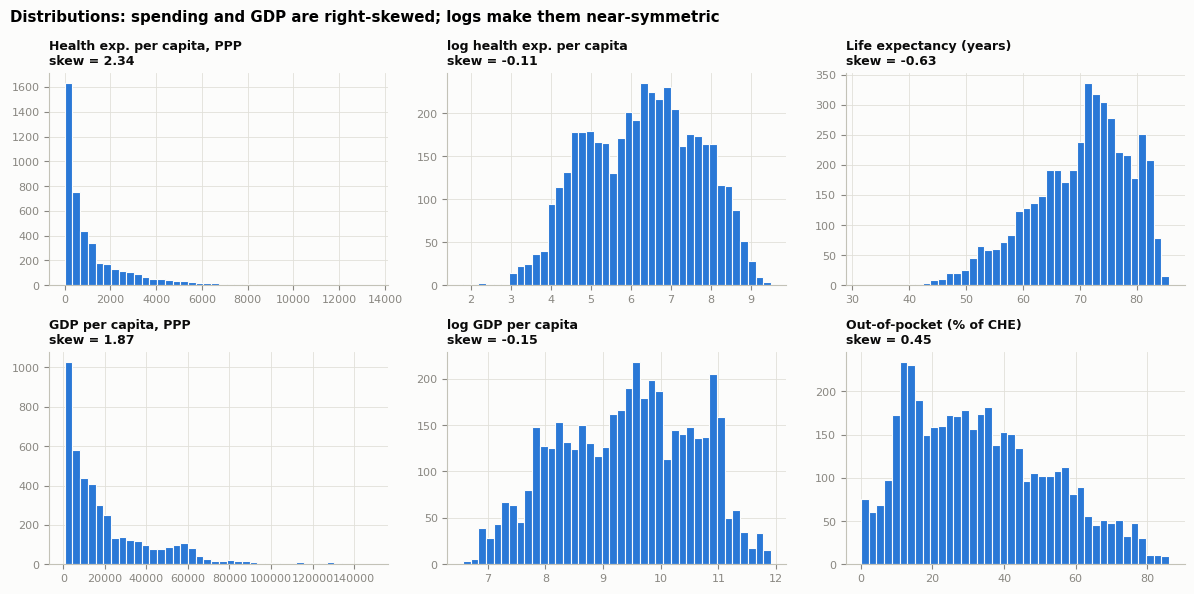

In [19]:
fig, axes = plt.subplots(2, 3, figsize=(12, 6))
pairs = [("che_pc_ppp", "Health exp. per capita, PPP"), ("log_che_pc_ppp", "log health exp. per capita"),
         ("life_exp", "Life expectancy (years)"), ("gdp_pc_ppp", "GDP per capita, PPP"),
         ("log_gdp_pc_ppp", "log GDP per capita"), ("oop_pct_che", "Out-of-pocket (% of CHE)")]
for ax, (v, t) in zip(axes.flat, pairs):
    ax.hist(df[v], bins=40, color=SERIES[0], edgecolor=SURFACE, linewidth=0.8)
    ax.set_title(f"{t}\nskew = {df[v].skew():.2f}", loc="left", fontsize=9)
fig.suptitle("Distributions: spending and GDP are right-skewed; logs make them near-symmetric", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "fig02_distributions.png")

Each panel is a histogram of all 4,404 country-years. The horizontal axis is the value, and the bar height is how many country-years fall in that range. The *skew* number measures how lopsided the shape is: 0 is symmetric, a positive value means a long tail to the right.

- **Spending per person (skew 2.34) and GDP per person (1.87)** are piled up at low values with a long right tail. Most country-years spend under $2,000 per person, while a few spend more than $10,000. In 2023 spending ranges from $28 (Sudan) to $13,473 (United States), a factor of almost 500.
- **After taking logs, both become nearly symmetric** (skew −0.11 and −0.15). This is why the models use log spending and log GDP: a few very rich countries no longer dominate the fit.
- **Life expectancy is mildly skewed to the left** (−0.63). Most country-years lie between 65 and 82 years, with a thin tail of low values from crisis countries.
- **The out-of-pocket share** is spread widely, from 0% to 86%, and is only mildly skewed (0.45), so it is used without a log.

### 4.3 Trends over time by income group

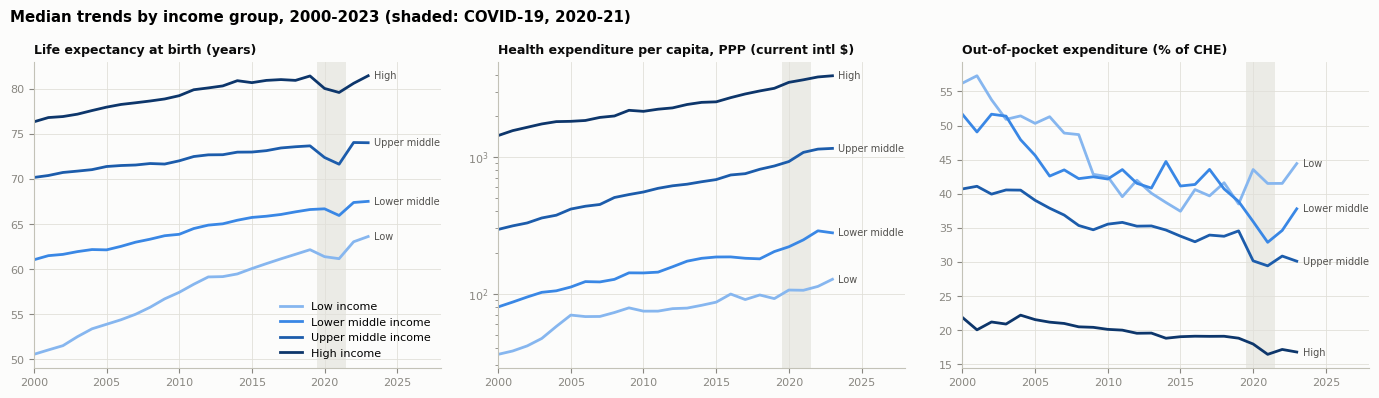

In [20]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, v in zip(axes, ["life_exp", "che_pc_ppp", "oop_pct_che"]):
    med = df.groupby(["year", "income_group"])[v].median().unstack()[INCOME_ORDER]
    for g in INCOME_ORDER:
        ax.plot(med.index, med[g], color=INCOME_COLORS[g], label=g)
        ax.text(med.index[-1] + 0.4, med[g].iloc[-1], g.replace(" income", ""), fontsize=7, color=INK2, va="center")
    if v == "che_pc_ppp":
        ax.set_yscale("log")
    ax.set_xlim(2000, 2028)
    ax.axvspan(2019.5, 2021.5, color=GRID, alpha=0.6, lw=0)
    ax.set_title(LABELS[v], loc="left", fontsize=9)
axes[0].legend(loc="lower right")
fig.suptitle("Median trends by income group, 2000-2023 (shaded: COVID-19, 2020-21)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "fig03_trends_by_income.png")

- Life expectancy rose in every income group, fastest in low-income countries (median +11.6 years from 2000 to 2019), before the COVID-19 dip.
- Spending rose steadily in all groups; the vertical gaps on the log scale stay roughly constant.
- The out-of-pocket share fell sharply in poorer countries during the 2000s.

### 4.4 Spending vs life expectancy (latest year)

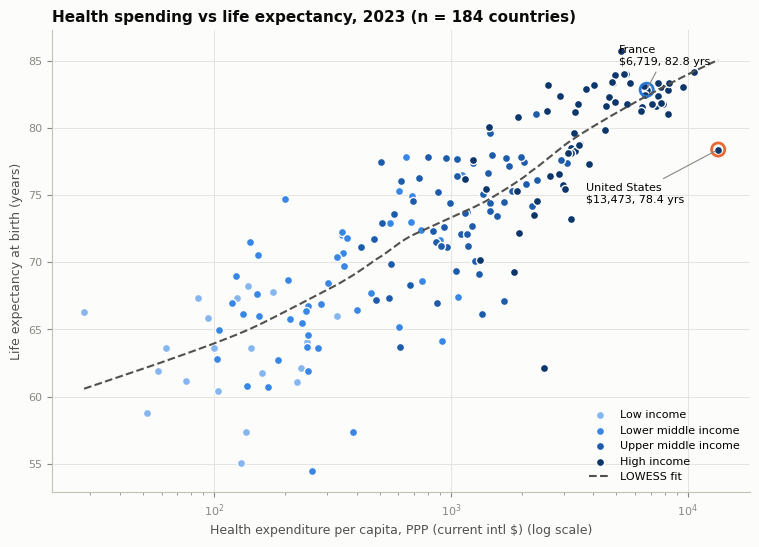

In [21]:
LATEST = int(df.groupby("year")["iso3"].nunique().loc[lambda s: s >= 180].index.max())
lat = df[df.year == LATEST]

fig, ax = plt.subplots(figsize=(9, 6))
for g in INCOME_ORDER:
    s = lat[lat.income_group == g]
    ax.scatter(s.che_pc_ppp, s.life_exp, s=34, color=INCOME_COLORS[g], label=g, edgecolor=SURFACE, linewidth=1)
fit = lowess(lat.life_exp, lat.log_che_pc_ppp, frac=0.5)
ax.plot(np.exp(fit[:, 0]), fit[:, 1], color=INK2, lw=1.5, ls="--", label="LOWESS fit")
for iso, name in HIGHLIGHT.items():
    r = lat[lat.iso3 == iso].iloc[0]
    ax.scatter(r.che_pc_ppp, r.life_exp, s=90, facecolor="none", edgecolor=COUNTRY_COLORS[iso], lw=2)
    ax.annotate(f"{name}\n${r.che_pc_ppp:,.0f}, {r.life_exp:.1f} yrs", (r.che_pc_ppp, r.life_exp),
                xytext=(-95 if iso == "USA" else -20, -38 if iso == "USA" else 18), textcoords="offset points",
                fontsize=8, arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.8))
ax.set_xscale("log")
ax.set_xlabel(LABELS["che_pc_ppp"] + " (log scale)")
ax.set_ylabel(LABELS["life_exp"])
ax.set_title(f"Health spending vs life expectancy, {LATEST} (n = {len(lat)} countries)", loc="left")
ax.legend(loc="lower right")
save(fig, "fig04_scatter_spending_life_exp.png")

Life expectancy rises roughly **linearly with log spending**: each doubling of spending goes with a similar gain. The United States is a clear outlier, with the highest spending and lower life expectancy than most high-income countries.

### 4.5 Group comparisons (boxplots)

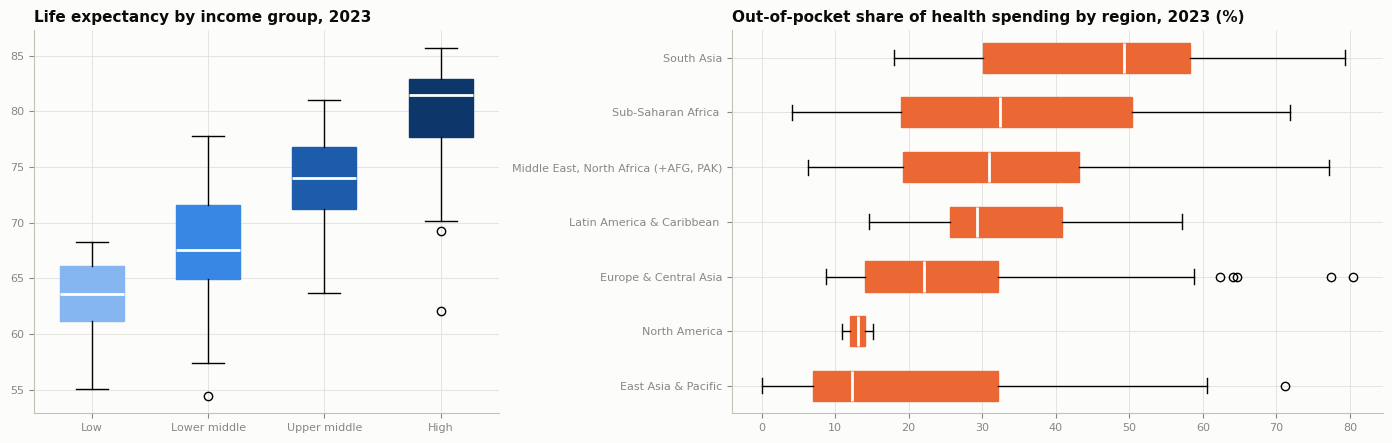

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 1.4]})
bp = axes[0].boxplot([lat[lat.income_group == g].life_exp for g in INCOME_ORDER], patch_artist=True, widths=0.55,
                     medianprops=dict(color="white", lw=2))
for patch, g in zip(bp["boxes"], INCOME_ORDER):
    patch.set(facecolor=INCOME_COLORS[g], edgecolor=INCOME_COLORS[g])
axes[0].set_xticks(range(1, 5), [g.replace(" income", "") for g in INCOME_ORDER])
axes[0].set_title(f"Life expectancy by income group, {LATEST}", loc="left")

regions = lat.groupby("region").oop_pct_che.median().sort_values().index
axes[1].boxplot([lat[lat.region == r].oop_pct_che for r in regions], vert=False, patch_artist=True, widths=0.55,
                boxprops=dict(facecolor=SERIES[1], edgecolor=SERIES[1]), medianprops=dict(color="white", lw=2))
axes[1].set_yticks(range(1, len(regions) + 1), [r.replace(", Afghanistan & Pakistan", " (+AFG, PAK)") for r in regions])
axes[1].set_title(f"Out-of-pocket share of health spending by region, {LATEST} (%)", loc="left")
fig.tight_layout()
save(fig, "fig05_boxplots.png")

Each box covers the middle half of countries (25th to 75th percentile) and the white line is the median. The whiskers reach the furthest country within 1.5 box-lengths of the box, and circles mark countries beyond that.

- **Left panel: life expectancy rises step by step with income.** The 2023 medians are 63.6 years (low income), 67.5 (lower middle), 74.0 (upper middle) and 81.4 (high income), almost 18 years between the poorest and richest groups.
- **The groups overlap.** The best low-income country (68.3 years) does better than the worst country in every other group. The two high-income circles are the small Pacific islands Nauru (62.1) and Palau (69.3); the circle below the lower-middle box is Nigeria (54.5).
- **Right panel: regions are sorted by their median out-of-pocket share.** South Asia relies most on direct payments (median 49%), and East Asia & Pacific (12%) and North America (13%) the least. North America's box is very narrow because it contains only the United States and Canada.
- **Europe & Central Asia** has a low median (22%), but the circles on the right are former Soviet countries where patients pay most costs directly: Armenia (81%), Turkmenistan (77%), and Azerbaijan, Uzbekistan and Tajikistan (62–65%). The circle in East Asia & Pacific is Myanmar (71%).

### 4.6 Correlations

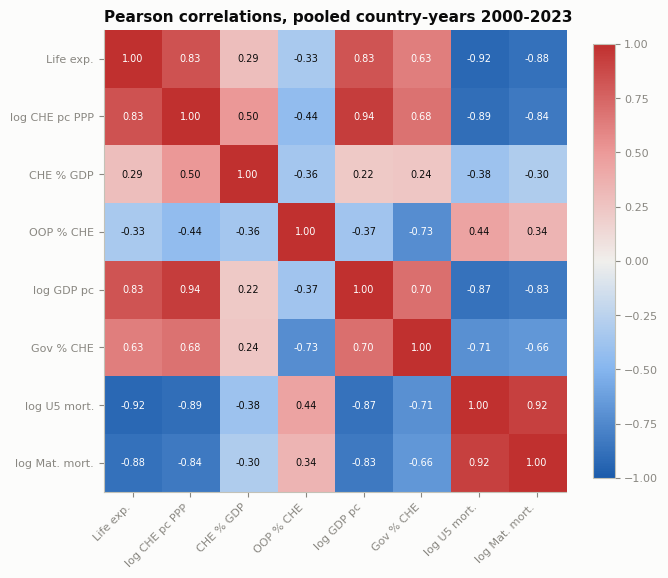

In [23]:
corr_vars = ["life_exp", "log_che_pc_ppp", "che_pct_gdp", "oop_pct_che", "log_gdp_pc_ppp", "gov_pct_che", "log_u5_mort", "log_mat_mort"]
names = ["Life exp.", "log CHE pc PPP", "CHE % GDP", "OOP % CHE", "log GDP pc", "Gov % CHE", "log U5 mort.", "log Mat. mort."]
corr = df[corr_vars].corr()
corr.to_csv(TABLE_DIR / "eda_correlations.csv")

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr.values, cmap=DIV_CMAP, vmin=-1, vmax=1)
ax.set_xticks(range(len(names)), names, rotation=45, ha="right")
ax.set_yticks(range(len(names)), names)
ax.grid(False)
for (i, j), v in np.ndenumerate(corr.values):
    ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=7, color="white" if abs(v) > 0.6 else INK)
fig.colorbar(im, ax=ax, fraction=0.04)
ax.set_title("Pearson correlations, pooled country-years 2000-2023", loc="left")
save(fig, "fig06_correlations.png")

- Life expectancy correlates strongly with **log spending (r = 0.83)**, and just as strongly with **log GDP (r = 0.83)**. Spending and GDP are themselves highly correlated (r ≈ 0.94).
- Because spending and GDP move together, regression models must separate their roles (Section 5).
- Spending as a share of GDP is only weakly related to life expectancy (r = 0.29).

### 4.7 Out-of-pocket burden vs life expectancy

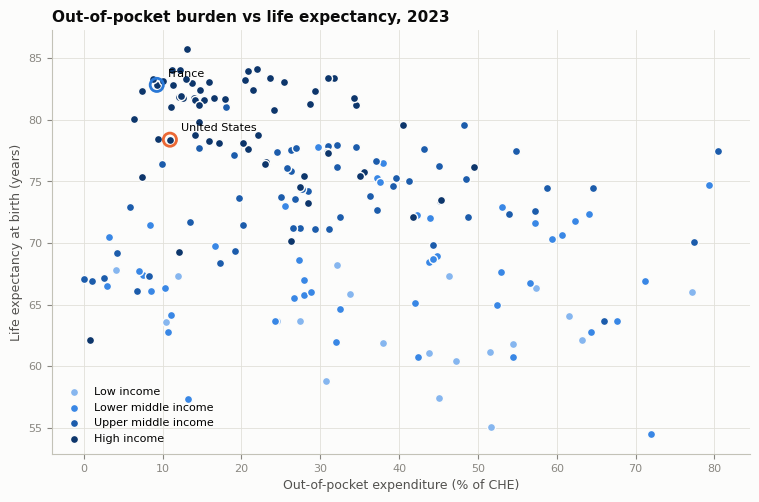

In [24]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for g in INCOME_ORDER:
    s = lat[lat.income_group == g]
    ax.scatter(s.oop_pct_che, s.life_exp, s=34, color=INCOME_COLORS[g], label=g, edgecolor=SURFACE, linewidth=1)
for iso, name in HIGHLIGHT.items():
    r = lat[lat.iso3 == iso].iloc[0]
    ax.scatter(r.oop_pct_che, r.life_exp, s=90, facecolor="none", edgecolor=COUNTRY_COLORS[iso], lw=2)
    ax.annotate(name, (r.oop_pct_che, r.life_exp), xytext=(8, 6), textcoords="offset points", fontsize=8)
ax.set_xlabel(LABELS["oop_pct_che"]); ax.set_ylabel(LABELS["life_exp"])
ax.set_title(f"Out-of-pocket burden vs life expectancy, {LATEST}", loc="left")
ax.legend(loc="lower left")
save(fig, "fig07_oop_vs_life_exp.png")

Each dot is one country in 2023. The horizontal position is the share of health spending paid directly by patients, the vertical position is life expectancy, and the colour is the income group. France and the United States are circled.

- **Overall, countries with higher out-of-pocket shares tend to live shorter lives** (correlation −0.32), but the dots are widely scattered.
- **Much of this pattern comes from income.** High-income countries (dark blue) cluster in the top-left corner (low out-of-pocket share, long lives), while poorer countries spread across higher shares and lower life expectancy. Within a single income group the correlation is weak and changes sign: −0.26 (low), +0.06 (lower middle), +0.23 (upper middle) and −0.20 (high). Section 7 tests this formally.
- **France and the United States have similar out-of-pocket shares** (9.3% and 10.9%) but a 4.4-year gap in life expectancy, so the out-of-pocket share alone cannot explain their difference.

### 4.8 Choropleth maps

The maps show geographic differences in spending, out-of-pocket burden and life expectancy. Static PNG versions are saved in `outputs/figures/` and shown below so they display on GitHub; interactive HTML versions are saved in `outputs/maps/`.

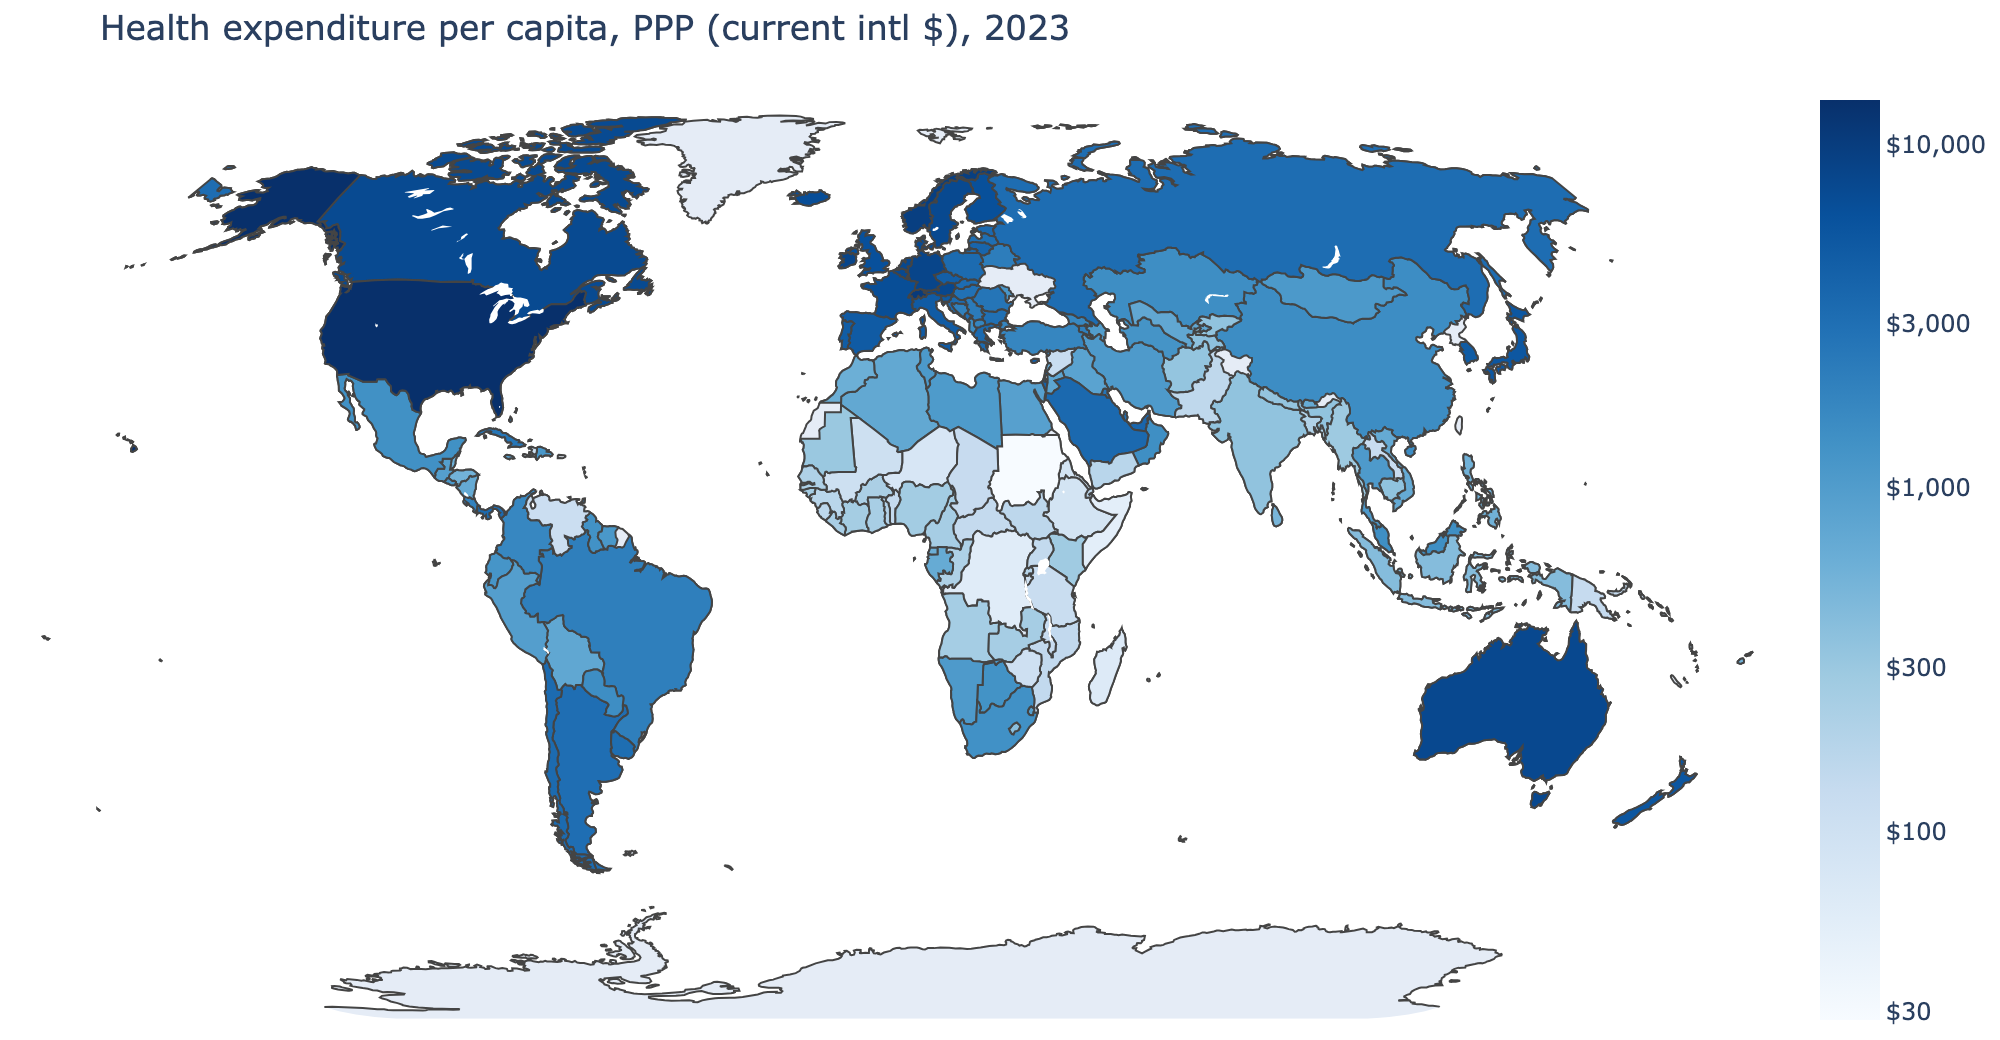

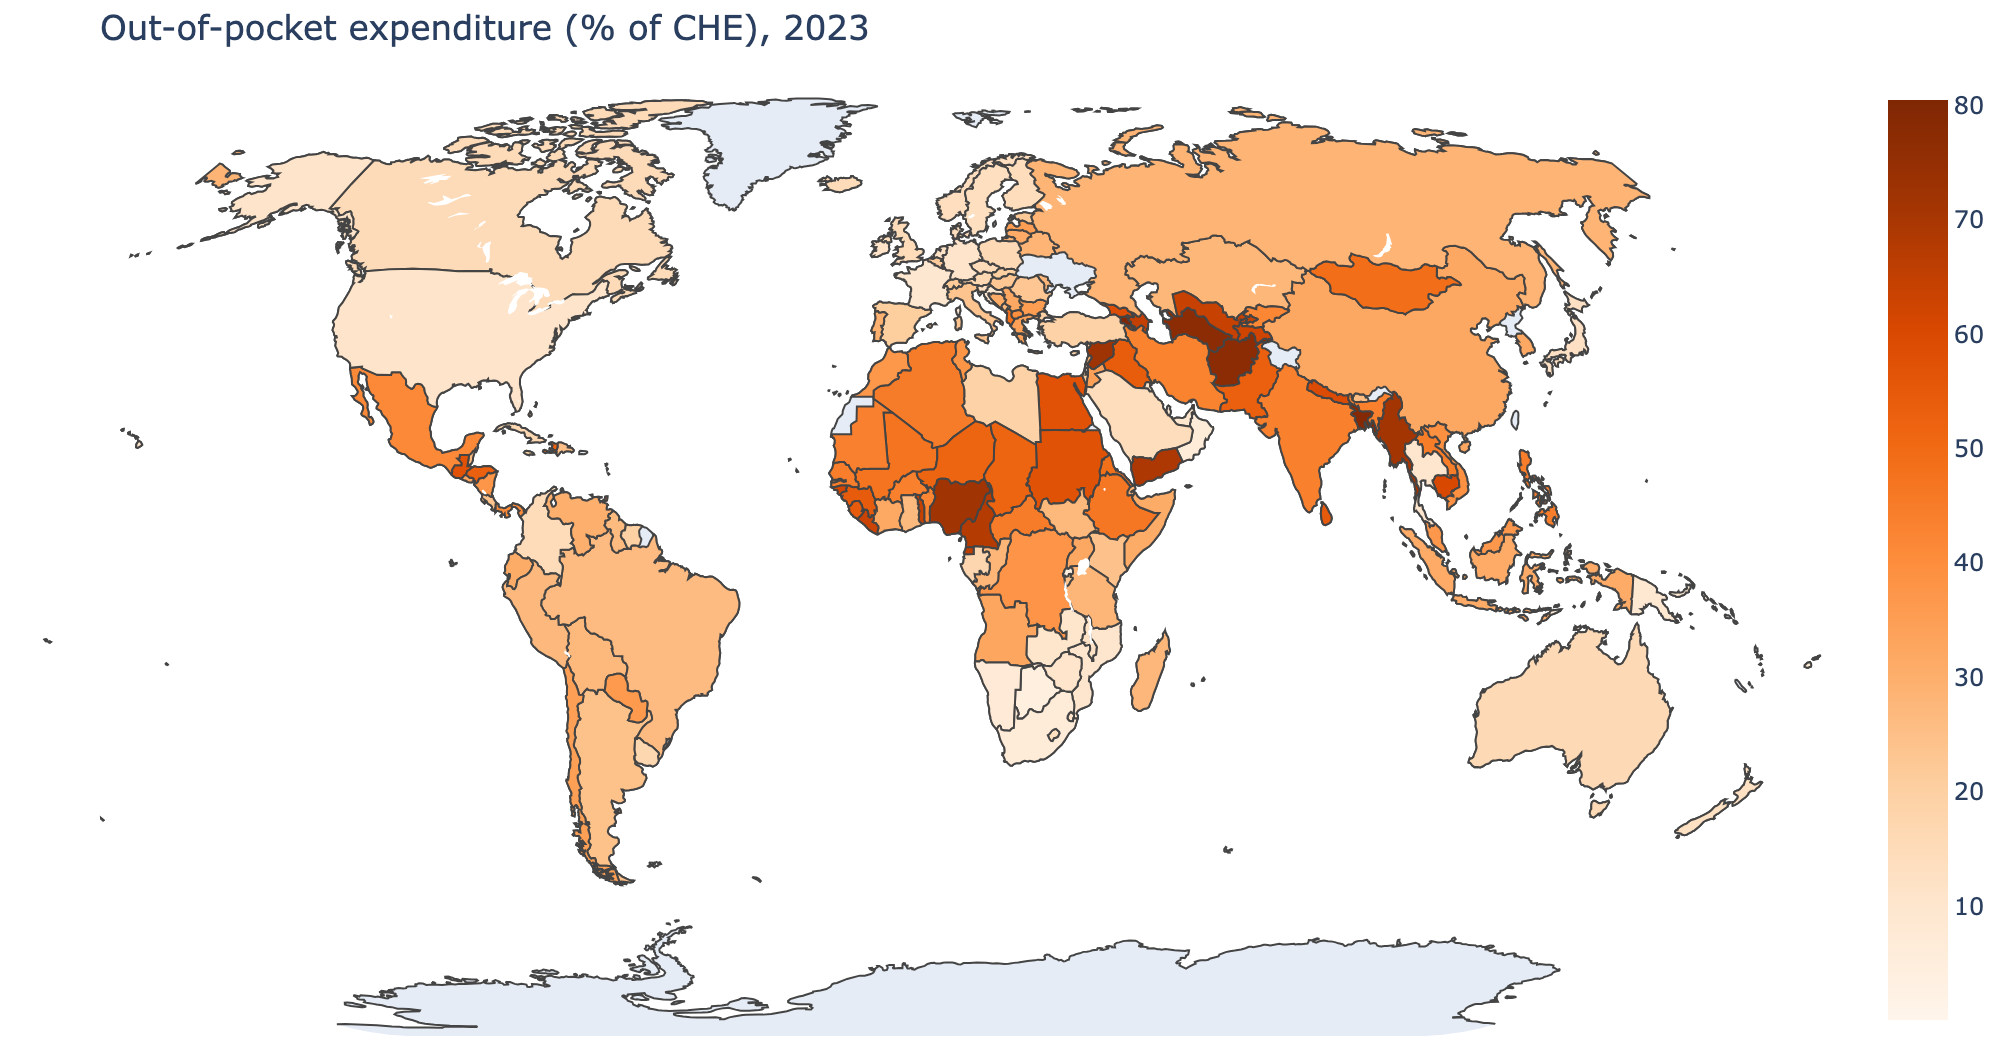

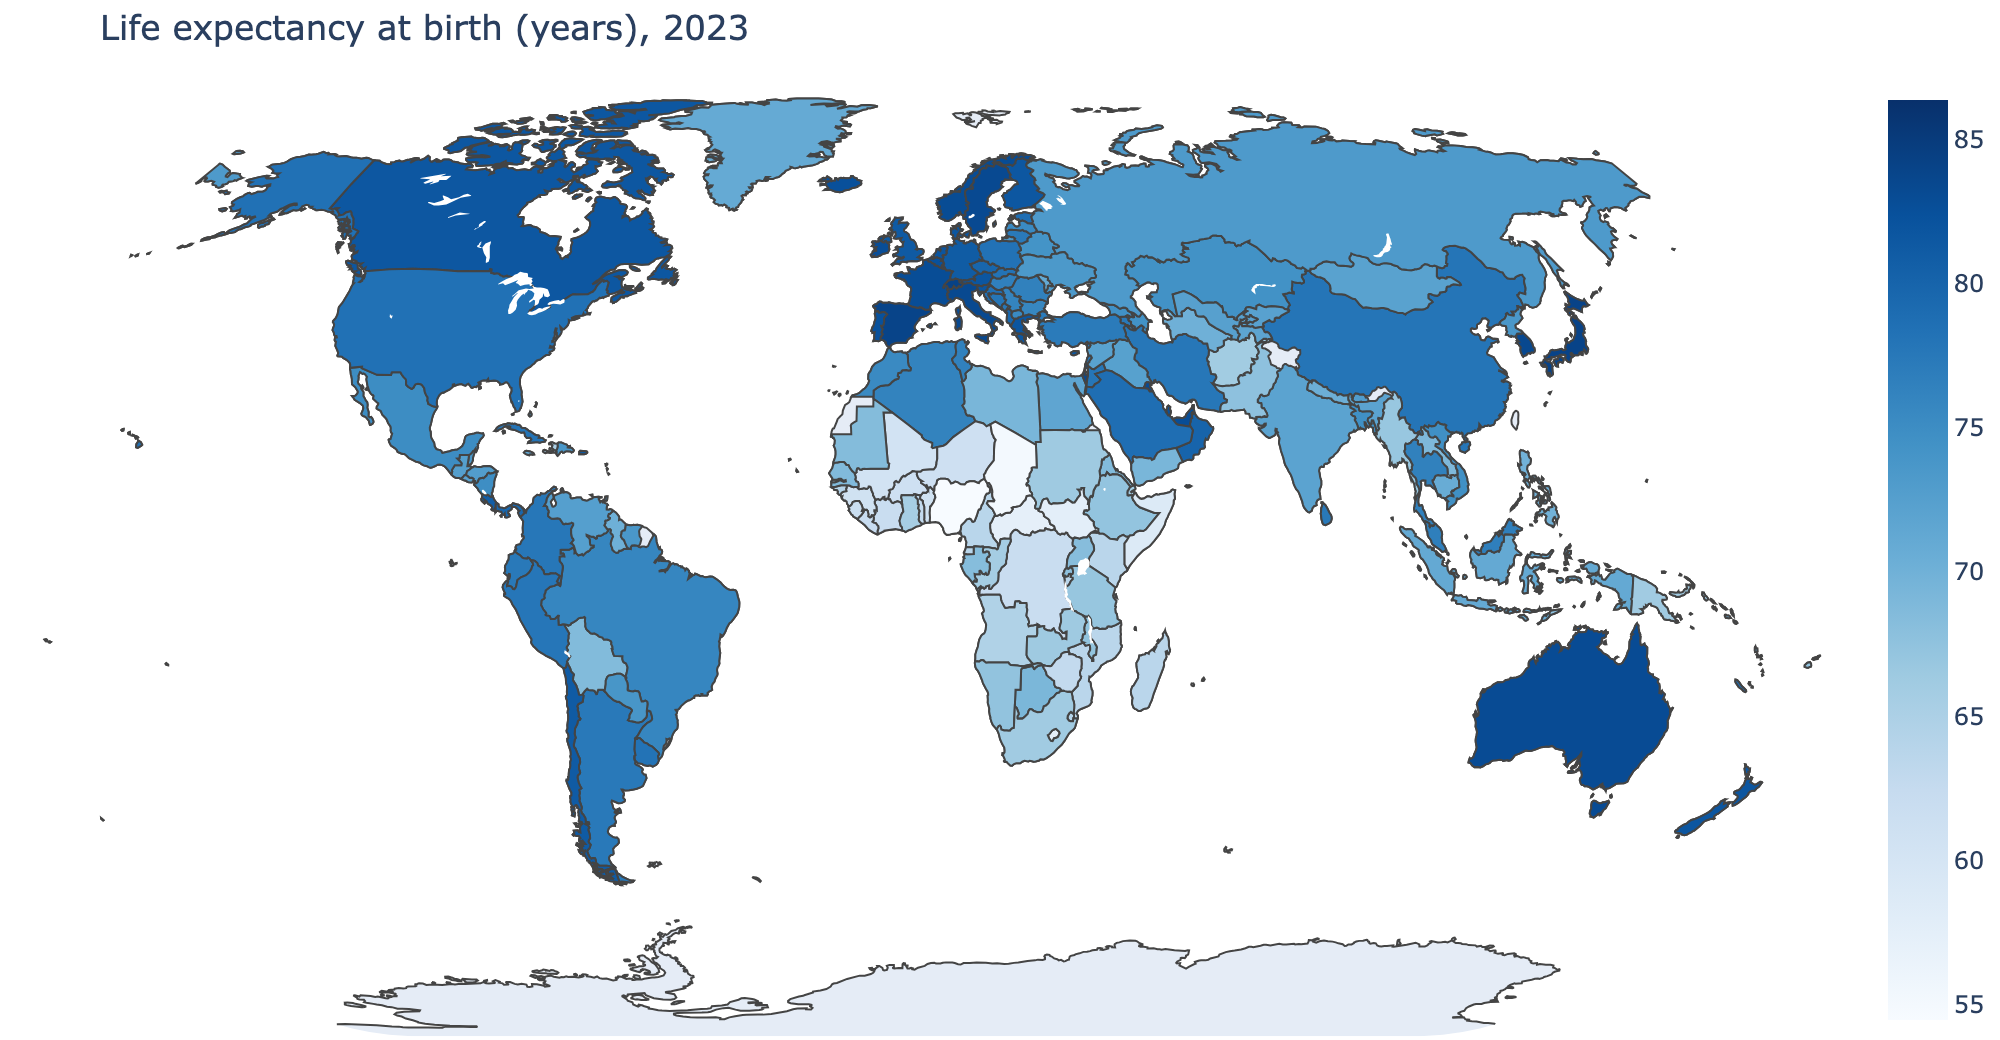

In [25]:

map_specs = [
    ("che_pc_ppp", "Blues", True),
    ("oop_pct_che", "Oranges", False),
    ("life_exp", "Blues", False)
]

for v, scale, logc in map_specs:
    d = panel[panel.year == LATEST].dropna(subset=[v]).copy()
    d["color"] = np.log10(d[v]) if logc else d[v]

    fig = px.choropleth(
        d,
        locations="iso3",
        color="color",
        hover_name="country",
        hover_data={v: ":,.1f", "iso3": False, "color": False},
        color_continuous_scale=scale,
        title=f"{LABELS[v]}, {LATEST}"
    )

    if logc:
        ticks = [30, 100, 300, 1000, 3000, 10000]
        fig.update_coloraxes(
            colorbar=dict(
                tickvals=np.log10(ticks),
                ticktext=[f"${t:,}" for t in ticks],
                title=""
            )
        )
    else:
        fig.update_coloraxes(colorbar_title="")

    fig.update_layout(
        margin=dict(l=0, r=0, t=40, b=0),
        geo=dict(showframe=False, projection_type="natural earth")
    )

    # Save interactive HTML map
    fig.write_html(
        MAP_DIR / f"map_{v}_{LATEST}.html",
        include_plotlyjs=True
    )

    # Save a static PNG (displays on GitHub) and show it
    png = FIG_DIR / f"map_{v}_{LATEST}.png"
    for attempt in range(4):              # kaleido's headless browser occasionally fails to start; retry
        try:
            fig.write_image(png, width=1000, height=520, scale=2)
            break
        except Exception:
            if attempt == 3:
                raise
    display(Image(filename=png, width=800))


Each country is coloured by its 2023 value; darker means higher. The spending map uses a **log colour scale** (each label on the legend is about three times the one below), otherwise the United States would make all other countries look alike. Grey areas have no data for that indicator: mostly small territories, plus Greenland, North Korea, Kosovo and, for 2022–23, Ukraine. Antarctica is not part of the data. Interactive versions with exact values on hover are in `outputs/maps/`.

- **Health spending** is highest in North America, Western Europe and Australia, and lowest across Sub-Saharan Africa and parts of South Asia.
- **Life expectancy** follows almost the same geography. The lowest values are in West and Central Africa (Nigeria 54.5, Chad 55.1, Central African Republic 57.4) and in Lesotho (57.4) in southern Africa; the highest are in Western Europe, Japan and Australia.
- **The out-of-pocket share** is highest in South and Central Asia and parts of Africa: Armenia (81%), Bangladesh (79%), Turkmenistan (77%), Afghanistan (77%), Nigeria (72%) and Myanmar (71%). It is low in North America, Western Europe and Australia, and also in much of southern Africa (South Africa 7%, Botswana 4%), where the government share of spending is high (62% in South Africa, 76% in Botswana).
- **Takeaway:** high spending, long lives and low out-of-pocket shares are found in the same, mostly rich, regions. Because they move together, the regressions in Section 5 must separate their roles, for example by controlling for GDP.

### 4.9 France and the United States within the high-income group

The proposal highlights these two countries as examples within the global analysis. It is a common comparison: healthcare is often called "free" in France, yet it is financed through taxes, social contributions, complementary insurance and direct payments.

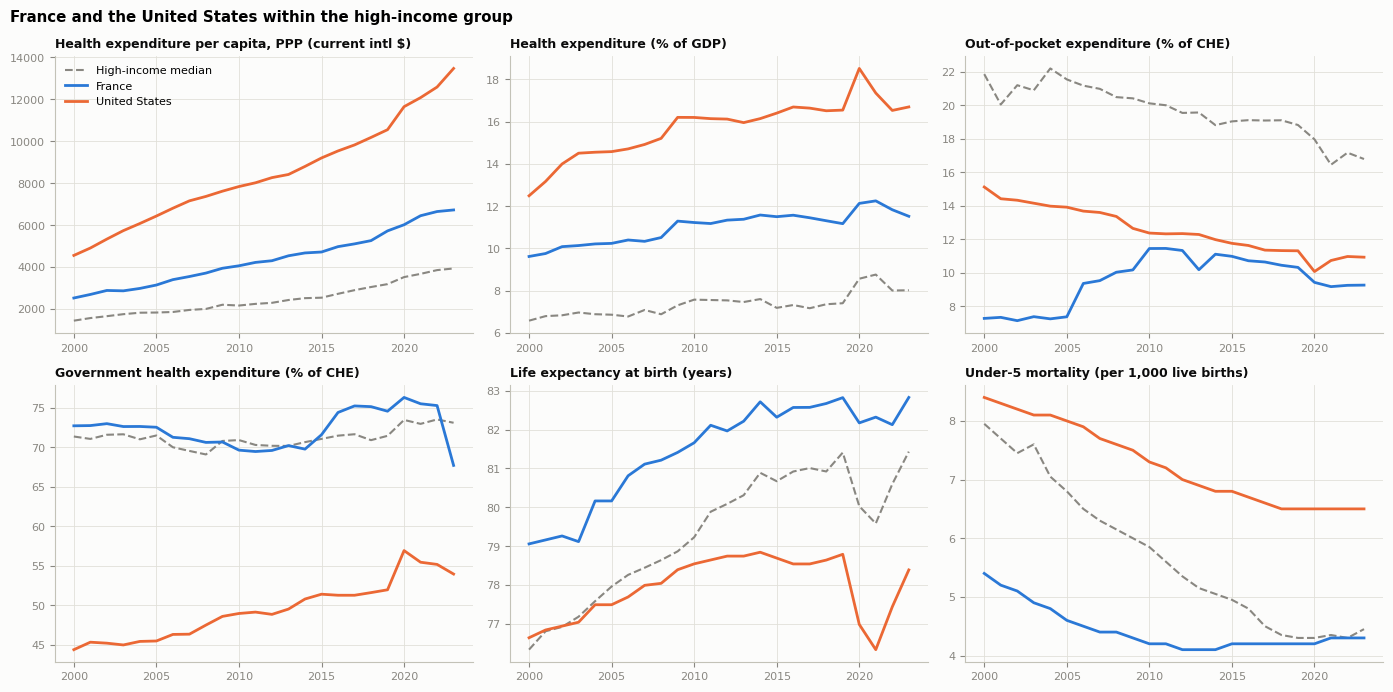

che_pc_ppp  che_pct_gdp  oop_pct_che  gov_pct_che  life_exp  u5_mort  gdp_pc_ppp  estimated_oop_pc_ppp
country       year                                                                                                        
France        2000   2,516.100        9.600        7.300       72.700    79.100    5.400  45,922.500               183.000
              2010   4,053.700       11.200       11.400       69.600    81.700    4.200  49,130.400               463.900
              2019   5,719.300       11.200       10.300       74.600    82.800    4.200  53,448.600               590.200
              2023   6,719.100       11.500        9.300       67.700    82.800    4.300  54,296.700               622.200
United States 2000   4,548.600       12.500       15.100       44.400    76.600    8.400  55,045.700               687.600
              2010   7,836.100       16.200       12.400       49.000    78.500    7.300  59,797.100               969.200
              2019  10,550.200       16.500       11.300       52.000    78.800    6.500  69,121.500             1,193.100
              2023  13,473.200       16.700       10.900       54.000    78.400    6.500  74,351.700             1,472.200

High-income median estimated OOP spending per capita: $820 PPP (n=64)


In [26]:
hi_med = df[df.income_group == "High income"].groupby("year")
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, v in zip(axes.flat, ["che_pc_ppp", "che_pct_gdp", "oop_pct_che", "gov_pct_che", "life_exp", "u5_mort"]):
    ax.plot(hi_med[v].median().index, hi_med[v].median().values, color=MUTED, lw=1.5, ls="--", label="High-income median")
    for iso, name in HIGHLIGHT.items():
        s = panel[panel.iso3 == iso]
        ax.plot(s.year, s[v], color=COUNTRY_COLORS[iso], label=name)
    ax.set_title(LABELS[v], loc="left", fontsize=9)
axes[0, 0].legend()
fig.suptitle("France and the United States within the high-income group", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
save(fig, "fig08_france_vs_usa.png")

fra_usa = (panel[panel.iso3.isin(HIGHLIGHT) & panel.year.isin([2000, 2010, 2019, LATEST])]
           .set_index(["country", "year"])[["che_pc_ppp", "che_pct_gdp", "oop_pct_che", "gov_pct_che", "life_exp", "u5_mort", "gdp_pc_ppp"]])

fra_usa["estimated_oop_pc_ppp"] = (
    fra_usa["che_pc_ppp"]
    * fra_usa["oop_pct_che"]
    / 100
)
hi_latest_oop = panel.loc[
    (panel["income_group"] == "High income")
    & (panel["year"] == LATEST),
    ["che_pc_ppp", "oop_pct_che"]
].dropna()

high_income_oop_pc_ppp_median = (
    hi_latest_oop["che_pc_ppp"]
    * hi_latest_oop["oop_pct_che"]
    / 100
).median()
fra_usa.to_csv(TABLE_DIR / "eda_france_vs_usa.csv")
display(fra_usa.round(1))

print(
    "High-income median estimated OOP spending per capita:",
    f"${high_income_oop_pc_ppp_median:,.0f} PPP",
    f"(n={len(hi_latest_oop)})"
)

Six indicators for 2000–2023, with the United States in orange, France in blue and the high-income median as a dashed grey line.

- US spending per person rises far above both France and the high-income median, and the gap widens over time.
- US life expectancy tracked the high-income median until the mid-2000s, then stalled and fell well below it. The COVID-19 drop was much deeper in the US (78.8 years in 2019 to 76.3 in 2021) than in France (82.8 to 82.3).
- Under-5 mortality fell in all three series, but the US stays above the high-income median and France below it.

**The table below the chart** gives exact values for selected years:

- **The US spends about twice as much per person as France** ($13,473 vs $6,719 in 2023) yet lives 4.4 years less. The gap widened from 2.5 years in 2000.
- **France is not "free" for patients.** Its out-of-pocket share (9.3%) is only slightly below the US share (10.9%). The World Bank/WHO GHED series used here reports domestic general government health expenditure at 67.7% of current health expenditure in France and 54.0% in the United States in 2023.
- **Similar out-of-pocket shares do not imply similar amounts.** Estimated out-of-pocket spending per capita in 2023 is about $622 PPP in France and $1,472 PPP in the United States, approximately 2.4 times as high in the US. This derived national average is not the exact amount paid by an individual household and does not capture the full burden of taxes, insurance premiums or deductibles.
- *Data comparability note:* France's value in the World Bank/WHO GHED series falls from 75.3% in 2022 to 67.7% in 2023, and the published value is retained here. A separate OECD/European Observatory measure reports 84.4% financed through government and compulsory schemes in 2023. These categories are not directly interchangeable, so the GHED value should be interpreted cautiously rather than manually replaced.

#### Context indicators for France and the United States

Spending alone does not explain the gap between the two countries. The table below adds five standard context measures, for the latest year (up to 2023) with data for both. Four come from the World Bank WDI; the coverage index comes from the WHO Global Health Observatory. They are shown **only here and are not used in any model**: they describe differences, not causes.

In [27]:
# Context indicators for the France-US comparison only (they are not used in any model)
CONTEXT_WDI = {
    "SI.POV.GINI":       "Income inequality, Gini index (0-100)",
    "SH.STA.OWAD.ZS":    "Overweight adults, BMI > 25 (%)",
    "SH.PRV.SMOK":       "Current tobacco use, adults (%)",
    "SP.POP.65UP.TO.ZS": "Population aged 65 and over (%)",
}

def collect_who(code):
    # Download one WHO Global Health Observatory indicator (or load the cached copy)
    path = RAW_DIR / f"WHO_{code}.json"
    if path.exists() and not REFRESH:
        return json.loads(path.read_text())
    rows = fetch_json(f"https://ghoapi.azureedge.net/api/{code}", {})["value"]
    path.write_text(json.dumps(rows))
    return rows

ctx = []
for code, label in CONTEXT_WDI.items():
    ctx += [{"iso3": r["countryiso3code"], "year": int(r["date"]), "indicator": label, "value": r["value"]}
            for r in collect_indicator(code)["rows"] if r["value"] is not None]
ctx += [{"iso3": r["SpatialDim"], "year": int(r["TimeDim"]), "indicator": "UHC service coverage index (0-100)", "value": r["NumericValue"]}
        for r in collect_who("UHC_INDEX_REPORTED") if r["SpatialDimType"] == "COUNTRY" and r["NumericValue"] is not None]
ctx = pd.DataFrame(ctx).merge(economies[["iso3", "income_group"]], on="iso3")

rows = []
for ind, g in ctx[ctx.year <= STUDY_END].groupby("indicator"):   # stay within the study window
    both = g[g.iso3.isin(HIGHLIGHT)].groupby("year").iso3.nunique()
    yr = both[both == 2].index.max()                     # latest year with data for both countries
    gy = g[g.year == yr]
    hi = gy[gy.income_group == "High income"]
    rows.append({"indicator": ind, "year": yr, "France": gy.loc[gy.iso3 == "FRA", "value"].item(),
                 "United States": gy.loc[gy.iso3 == "USA", "value"].item(),
                 "High-income median": hi.value.median(), "high-income countries with data": len(hi)})
context_tbl = pd.DataFrame(rows).set_index("indicator")
context_tbl.to_csv(TABLE_DIR / "eda_france_vs_usa_context.csv")
context_tbl.round(1)

,year,France,United States,High-income median,high-income countries with data
indicator,,,,,
"Current tobacco use, adults (%)",2023,33.400,16.400,21.500,57
"Income inequality, Gini index (0-100)",2023,31.800,41.800,31.800,31
"Overweight adults, BMI > 25 (%)",2022,34.300,72.400,60.700,66
Population aged 65 and over (%),2023,21.700,17.400,17.300,86
UHC service coverage index (0-100),2023,82.000,88.000,83.000,63


- **Income inequality** is much higher in the US (Gini 41.8 vs 31.8; France equals the high-income median).
- **Overweight adults:** 72.4% in the US vs 34.3% in France (high-income median 60.7%). France's figure is far below its neighbours in the same WHO source, for example Germany (about 54%) and Italy (about 49%), so treat it with caution.
- **Not every measure favours France.** Tobacco use is about twice as high in France (33.4% vs 16.4%), and France's population is older (21.7% aged 65+ vs 17.4%), which on its own would lower life expectancy, not raise it.
- **The UHC service coverage index is higher in the US (88 vs 82).** This index measures access to essential services such as vaccination and treatment of common diseases. It does not measure insurance coverage or financial protection, so it does not capture who is uninsured.
- **Takeaway:** inequality and overweight point in the expected direction, but tobacco and age do not. A few context measures cannot explain the gap; published research on the US–France difference would be needed to go further.

## 5. Panel regression analysis (main methodology)

Life expectancy in country *i* and year *t* is modelled as

$$\text{LE}_{it} = \beta \, \log(\text{CHE}_{it}) + \gamma' X_{it} + \alpha_i + \lambda_t + \varepsilon_{it}$$

- $\alpha_i$ — **country fixed effects** absorb stable differences between countries, such as geography, culture and institutions.
- $\lambda_t$ — **year fixed effects** absorb shocks common to all countries, such as global medical progress or COVID-19.
- $X_{it}$ — controls: log GDP per capita, and the out-of-pocket share (per 10 percentage points).
- **Standard errors are clustered by country**, because the same country is observed repeatedly.

**The methods in plain words**

- **Country fixed effects** compare each country with itself over time. Things that do not change, such as geography or culture, then cannot bias the result. The question becomes: *when a country spends more than it usually does, does it live longer than it usually does?*
- **Year fixed effects** remove what happened to all countries in the same year, such as new medicines or COVID-19. Without them, any two things that both rise over time look related.
- **Clustered standard errors.** The 24 years of one country are not 24 independent pieces of information. Clustering by country widens the uncertainty to reflect this; otherwise the p-values would be too small.
- **Hausman test** (end of this section). It helps choose between fixed effects and random effects, explained there.

The models are built up step by step to show how each element changes the estimate:

| Model | Description |
|---|---|
| (1) | Pooled OLS (no fixed effects); compares countries directly |
| (2) | Country fixed effects |
| (3) | Two-way fixed effects (country + year) |
| (4) | (3) + log GDP per capita |
| (5) | (4) + out-of-pocket share |
| (6) | (5) with a quadratic in log spending (nonlinear / diminishing returns) |

In [28]:
def fit_panel(data, y, xs, entity=True, time=True, cov="clustered", pooled=False):
    # Fit y ~ xs on the country-year panel (linearmodels). cov: 'clustered' (by country), 'kernel' (Driscoll-Kraay) or 'unadjusted'.
    d = data.dropna(subset=[y, *xs]).set_index(["iso3", "year"]).sort_index()
    if pooled:
        return PooledOLS(d[y], d[xs].assign(const=1.0)).fit(cov_type="clustered", cluster_entity=True)
    mod = PanelOLS(d[y], d[xs], entity_effects=entity, time_effects=time, drop_absorbed=True, check_rank=False)
    if cov == "clustered":
        return mod.fit(cov_type="clustered", cluster_entity=True)
    return mod.fit(cov_type=cov)

def coef_row(res, var, label, **extra):
    # Tidy summary of one coefficient
    ci = res.conf_int().loc[var]
    return {"model": label, "coef": res.params[var], "se": res.std_errors[var], "ci_low": ci.iloc[0], "ci_high": ci.iloc[1],
            "pvalue": res.pvalues[var], "nobs": int(res.nobs), "countries": int(res.entity_info["total"]), **extra}

stars = lambda p: "***" if p < 0.01 else "**" if p < 0.05 else "*" if p < 0.1 else ""

In [29]:
Y = "life_exp"
specs = [
    ("(1) Pooled OLS",  ["log_che_pc_ppp"], dict(pooled=True)),
    ("(2) Country FE",  ["log_che_pc_ppp"], dict(entity=True, time=False)),
    ("(3) Two-way FE",  ["log_che_pc_ppp"], dict(entity=True, time=True)),
    ("(4) + GDP",       ["log_che_pc_ppp", "log_gdp_pc_ppp"], {}),
    ("(5) + GDP + OOP", ["log_che_pc_ppp", "log_gdp_pc_ppp", "oop_10"], {}),
    ("(6) Nonlinear",   ["log_che_c", "log_che_c_sq", "log_gdp_pc_ppp", "oop_10"], {}),
]
main_results = {label: fit_panel(df, Y, xs, **kw) for label, xs, kw in specs}

term_names = {"log_che_pc_ppp": "log health exp. pc (PPP)", "log_che_c": "log health exp. pc (centred)",
              "log_che_c_sq": "log health exp. pc² (centred)", "log_gdp_pc_ppp": "log GDP pc (PPP)",
              "oop_10": "OOP share (per 10 pp)"}
table = {}
for label, res in main_results.items():
    col = {}
    for t, name in term_names.items():
        col[name] = f"{res.params[t]:.3f}{stars(res.pvalues[t])}" if t in res.params else ""
        col[name + " (SE)"] = f"({res.std_errors[t]:.3f})" if t in res.params else ""
    col["Country FE"] = "Yes" if getattr(res.model, "entity_effects", False) else "No"
    col["Year FE"] = "Yes" if getattr(res.model, "time_effects", False) else "No"
    col["Observations"] = f"{int(res.nobs):,}"
    col["Countries"] = int(res.entity_info["total"])
    col["R² (after fixed effects)"] = f"{res.rsquared:.3f}"
    table[label] = col
table = pd.DataFrame(table)
table.to_csv(TABLE_DIR / "models_main_table.csv")
print("Dependent variable: life expectancy (years). Country-clustered SEs. * p<0.1, ** p<0.05, *** p<0.01")
print("R² is measured after removing each model's own fixed effects, so it is not comparable between columns with different fixed effects.")
table

Dependent variable: life expectancy (years). Country-clustered SEs. * p<0.1, ** p<0.05, *** p<0.01
R² is measured after removing each model's own fixed effects, so it is not comparable between columns with different fixed effects.


,(1) Pooled OLS,(2) Country FE,(3) Two-way FE,(4) + GDP,(5) + GDP + OOP,(6) Nonlinear
log health exp. pc (PPP),5.216***,3.823***,0.543,-0.265,-0.294,
log health exp. pc (PPP) (SE),(0.192),(0.221),(0.374),(0.439),(0.439),
log health exp. pc (centred),,,,,,-0.997**
log health exp. pc (centred) (SE),,,,,,(0.400)
log health exp. pc² (centred),,,,,,-0.549***
log health exp. pc² (centred) (SE),,,,,,(0.083)
log GDP pc (PPP),,,,2.071***,2.119***,1.880***
log GDP pc (PPP) (SE),,,,(0.730),(0.741),(0.640)
OOP share (per 10 pp),,,,,-0.252*,-0.136
OOP share (per 10 pp) (SE),,,,,(0.128),(0.111)


**Interpretation**

1. **Across countries, the association is strong (model 1).** Each log unit of spending goes with 5.2 more years of life expectancy, so 10% more spending ↔ about **0.5 years**.
2. **Within countries, it is mostly a common global trend (models 2–3).** With country fixed effects the coefficient is 3.8, but once year fixed effects absorb worldwide progress it drops to 0.54 and is not significant.
3. **GDP per capita takes over (models 4–5).** With log GDP added, the spending coefficient is indistinguishable from zero (−0.29, p = 0.50), while GDP is significant (+2.1 years per log unit, so 10% more GDP ↔ about 0.2 years).
4. **Out-of-pocket share (model 5).** A 10-percentage-point higher out-of-pocket share is associated with about 0.25 fewer years. This is borderline (p = 0.05).
5. **Nonlinearity (model 6).** The squared term is negative and highly significant, which indicates **diminishing returns**. The implied within-country slope at each spending level is shown below.

**How to read the 0.5 years.** It compares *different countries*: countries that spend 10% more tend to live about half a year longer. It is **not** the effect of one country raising its spending by 10%. Countries that spend more also differ in income, education, sanitation, diet and many other ways that the model does not include. Within a country, spending and income grow together year by year; once global trends and GDP are taken out, little variation is left to link to life expectancy. That is why the within-country estimates are so much smaller.

*Earlier studies.* The studies in our proposal (Jaba et al. 2014; Ray & Linden 2020; Balkhi et al. 2021) used cross-country panel data for 1995–2015. The proposal summarises their data and methods but not their estimates, so we do not claim that our numbers match theirs.

In [30]:
nl = main_results["(6) Nonlinear"]
b1, b2, mean_log = nl.params["log_che_c"], nl.params["log_che_c_sq"], df["log_che_pc_ppp"].mean()
grid = pd.DataFrame({"che_pc_ppp ($)": [50, 100, 250, 500, 1000, 2500, 5000, 10000]})
grid["slope per log unit"] = b1 + 2 * b2 * (np.log(grid["che_pc_ppp ($)"]) - mean_log)
grid["years per +10% spending"] = grid["slope per log unit"] * np.log(1.1)
turning_point = np.exp(mean_log - b1 / (2 * b2))
grid.to_csv(TABLE_DIR / "models_nonlinear_marginal_effects.csv", index=False)
print(f"Turning point (within-country slope = 0): ${turning_point:,.0f} per capita (PPP)")
grid.round(3)

Turning point (within-country slope = 0): $220 per capita (PPP)


,che_pc_ppp ($),slope per log unit,years per +10% spending
0,50,1.625,0.155
1,100,0.864,0.082
2,250,-0.142,-0.014
3,500,-0.903,-0.086
4,1000,-1.664,-0.159
5,2500,-2.671,-0.255
6,5000,-3.432,-0.327
7,10000,-4.193,-0.400


The parabola gives a turning point of about **$220 per person**. About 71% of country-years spend more than that, so the parabola forces a *falling* slope for most of the data. Because a parabola is a rigid shape, we check it with a more flexible one: four separate straight-line slopes, for spending below $100, $100–500, $500–2,000 and above $2,000 per person.

In [31]:
# Flexible check: separate straight-line slopes in four spending bands instead of one parabola
KNOTS = [100, 500, 2000]
BANDS = ["< $100", "$100-500", "$500-2,000", "> $2,000"]
sp = df.copy()
sp["seg0"] = sp["log_che_pc_ppp"]
for j, k in enumerate(KNOTS, start=1):
    sp[f"seg{j}"] = np.clip(sp["log_che_pc_ppp"] - np.log(k), 0, None)   # extra slope that starts at each knot
segs = [f"seg{j}" for j in range(len(KNOTS) + 1)]

rows = []
for ctrl_label, ctrl in [("no controls", []), ("+ GDP + OOP", ["log_gdp_pc_ppp", "oop_10"])]:
    res = fit_panel(sp, Y, [*segs, *ctrl])
    for j, band in enumerate(BANDS):
        terms = segs[: j + 1]                                             # slope in a band = sum of the segment terms so far
        est, se = res.params[terms].sum(), np.sqrt(res.cov.loc[terms, terms].values.sum())
        rows.append({"controls": ctrl_label, "spending band": band, "slope per log unit": est, "se": se,
                     "p (approx.)": 2 * (1 - stats.norm.cdf(abs(est / se)))})
spline = pd.DataFrame(rows)
spline["country-years in band"] = spline["spending band"].map(
    pd.cut(df.che_pc_ppp, [0, *KNOTS, np.inf], labels=BANDS).value_counts())
spline.to_csv(TABLE_DIR / "models_spline_slopes.csv", index=False)
print(f"Share of country-years above the ${turning_point:,.0f} turning point: {(df.che_pc_ppp > turning_point).mean():.1%}")
spline.round(3)

Share of country-years above the $220 turning point: 70.8%


,controls,spending band,slope per log unit,se,p (approx.),country-years in band
0,no controls,< $100,3.524,0.797,0.000,579
1,no controls,$100-500,0.273,0.465,0.558,1427
2,no controls,"$500-2,000",-1.010,0.440,0.022,1502
3,no controls,"> $2,000",-1.637,0.613,0.008,896
4,+ GDP + OOP,< $100,2.772,0.786,0.000,579
5,+ GDP + OOP,$100-500,-0.724,0.466,0.120,1427
6,+ GDP + OOP,"$500-2,000",-2.011,0.481,0.000,1502
7,+ GDP + OOP,"> $2,000",-2.106,0.558,0.000,896


- **The flexible check agrees with the parabola.** Within countries, the slope is clearly positive only below $100 (about 2.8–3.5 years per log unit, p < 0.001), close to zero at $100–500, and **negative above $500** (about −1.0 to −2.1).
- **How to read the negative slope.** It does not mean that spending shortens lives. With year fixed effects, every country is compared with the *global* trend of that year. Poorer countries gained life expectancy much faster (median +11.6 years in low-income vs +5.1 in high-income countries, 2000–2019), so high-spending countries look as if they gain less than the global trend while their spending keeps rising. This is a likely explanation, but our models do not test it directly.
- **The turning point is approximate:** $220 here, about $250 without the COVID years, and about $290 with spending in constant prices (Section 6). We describe it as "roughly $200–300 per person".

### Fixed vs random effects (Hausman test)

Random effects is more precise than fixed effects, but it is only valid if the unobserved country traits are unrelated to spending. The Hausman test compares the two sets of estimates. If they differ a lot (small p-value), those traits are related to spending, and fixed effects is the safe choice.

*Note.* The classic Hausman test assumes independent, equal-variance errors, but elsewhere we cluster errors by country. We therefore also run a **cluster-robust Mundlak test**: each country's averages of the regressors are added to a pooled model with year dummies, and we test whether they matter. If they do, country traits are related to the regressors, and fixed effects is again preferred.

In [32]:
year_dummies = pd.get_dummies(df["year"], prefix="y", drop_first=True, dtype=float)
dh = pd.concat([df, year_dummies], axis=1)
xs_h = ["log_che_pc_ppp", "log_gdp_pc_ppp", "oop_10", *year_dummies.columns]

fe_h = fit_panel(dh, Y, xs_h, entity=True, time=False, cov="unadjusted")
d_re = dh.set_index(["iso3", "year"])
re_h = RandomEffects(d_re[Y], d_re[xs_h].assign(const=1.0)).fit()

common = [c for c in fe_h.params.index if c in re_h.params.index]
b = fe_h.params[common] - re_h.params[common]
V = fe_h.cov.loc[common, common] - re_h.cov.loc[common, common]
H = float(b.T @ np.linalg.pinv(V.values) @ b)
p_h = 1 - stats.chi2.cdf(H, len(common))
p_txt = "< 0.001" if p_h < 0.001 else f"= {p_h:.3f}"
print(f"Hausman test: chi2({len(common)}) = {H:.1f}, p {p_txt}  ->  {'fixed effects preferred' if p_h < 0.05 else 'random effects not rejected'}")
# Cluster-robust alternative (Mundlak): add country means of the regressors and test them jointly
X_M = ["log_che_pc_ppp", "log_gdp_pc_ppp", "oop_10"]
dm = df.assign(**{f"mean_{v}": df.groupby("iso3")[v].transform("mean") for v in X_M})
mundlak = smf.ols(f"{Y} ~ " + " + ".join(X_M + [f"mean_{v}" for v in X_M]) + " + C(year)", dm).fit(
    cov_type="cluster", cov_kwds={"groups": pd.factorize(dm["iso3"])[0]})
w = mundlak.wald_test(", ".join(f"mean_{v} = 0" for v in X_M), scalar=True, use_f=False)
p_m = float(w.pvalue)
print(f"Mundlak test (country-clustered): chi2({len(X_M)}) = {float(w.statistic):.1f}, p {'< 0.001' if p_m < 0.001 else f'= {p_m:.3f}'}"
      f"  ->  {'fixed effects preferred' if p_m < 0.05 else 'random effects not rejected'}")

Hausman test: chi2(26) = 183.0, p < 0.001  ->  fixed effects preferred
Mundlak test (country-clustered): chi2(3) = 42.7, p < 0.001  ->  fixed effects preferred


## 6. Robustness and heterogeneity analyses

Both tests reject random effects (Hausman χ²(26) = 183.0; cluster-robust Mundlak χ²(3) = 42.7; both p < 0.001), so all checks use fixed effects. Each check re-estimates the two-way fixed-effects model under an alternative analytical choice. It is fitted twice: **without controls**, and **with GDP + out-of-pocket share**.

| Check | Purpose |
|---|---|
| Spending as % of GDP; current US$; constant 2021 PPP $ | Alternative spending measures (proposal; constant prices answer the current-vs-constant question) |
| Balanced panel | Consistent country sample (proposal) |
| Exclude COVID years / pre-COVID only | Does the 2020–21 shock drive results? |
| Exclude flagged outliers | Sensitivity to outliers (Section 3.7) |
| Driscoll-Kraay SEs | Standard errors that also allow countries to be hit by the same shock in the same year |
| Lagged spending (1, 3, 5 years) | Health effects may take time |
| 5-year averages, long difference | Reduce year-to-year noise |
| Between estimator (country means) | Pure cross-country comparison |
| Income groups, regions, periods | Heterogeneity (proposal) |
| Under-5 and maternal mortality | Other outcomes (extension) |

In [33]:
SPEND, BASE_X = "log_che_pc_ppp", ["log_gdp_pc_ppp", "oop_10"]
rob = []

def run(label, data, spend=SPEND, group="Specification", **kw):
    # Fit spending-only and full-control two-way FE models and store the spending coefficient
    for ctrl_label, ctrl in [("no controls", []), ("+ GDP + OOP", BASE_X)]:
        try:
            rob.append(coef_row(fit_panel(data, Y, [spend, *ctrl], **kw), spend, label, group=group, controls=ctrl_label, spend_var=spend))
        except Exception as e:
            print(f"skipped {label} / {ctrl_label}: {e}")

def ols_row(label, formula, data, term):
    # OLS with robust (HC1) SEs for cross-sectional variants
    for ctrl_label, f in formula.items():
        m = smf.ols(f, data).fit(cov_type="HC1")
        rob.append({"model": label, "coef": m.params[term], "se": m.bse[term], "ci_low": m.conf_int().loc[term, 0],
                    "ci_high": m.conf_int().loc[term, 1], "pvalue": m.pvalues[term], "nobs": int(m.nobs), "countries": int(m.nobs),
                    "group": "Specification", "controls": ctrl_label, "spend_var": SPEND})

# --- Alternative specifications ---
run("Baseline", df)
run("Spending as % of GDP", df, spend="che_pct_gdp")
run("Spending in current US$ (log)", df, spend="log_che_pc_usd")
df["log_che_const"] = np.log(df["che_pct_gdp"] * df["gdp_pc_ppp"] / 100)   # spending in constant 2021 intl $ = share of GDP x constant GDP
run("Spending in constant 2021 PPP $ (log)", df, spend="log_che_const")
run("Balanced panel", df[df.balanced])
run("Excluding COVID years 2020-21", df[~df.covid])
run("Pre-COVID only (2000-2019)", df[df.year <= 2019])
run("Excluding flagged outliers", df[~df.flag_outlier & ~df.flag_invalid])
run("Driscoll-Kraay SEs", df, cov="kernel")

dl = df.copy()
for k in (1, 3, 5):
    # Lag by calendar years (merge on year + k), not by rows: a country with a missing year would otherwise get the wrong lag
    lagged = df[["iso3", "year", SPEND]].assign(year=df["year"] + k).rename(columns={SPEND: f"log_che_lag{k}"})
    dl = dl.merge(lagged, on=["iso3", "year"], how="left")
    run(f"Spending lagged {k} year(s)", dl, spend=f"log_che_lag{k}")

d5 = df.assign(year=(df.year // 5) * 5).groupby(["iso3", "year"], as_index=False)[[Y, SPEND, *BASE_X]].mean()
run("5-year averages", d5)

w = df[df.year.isin([2000, 2019])].pivot(index="iso3", columns="year", values=[Y, SPEND, *BASE_X])
ld = pd.DataFrame({"d_le": w[(Y, 2019)] - w[(Y, 2000)], "d_che": w[(SPEND, 2019)] - w[(SPEND, 2000)],
                   "d_gdp": w[("log_gdp_pc_ppp", 2019)] - w[("log_gdp_pc_ppp", 2000)],
                   "d_oop": w[("oop_10", 2019)] - w[("oop_10", 2000)]}).dropna()
ols_row("Long difference 2000-2019", {"no controls": "d_le ~ d_che", "+ GDP + OOP": "d_le ~ d_che + d_gdp + d_oop"}, ld, "d_che")

cm = df.groupby("iso3")[[Y, SPEND, *BASE_X]].mean()
ols_row("Between countries (country means)", {"no controls": f"{Y} ~ {SPEND}", "+ GDP + OOP": f"{Y} ~ {SPEND} + log_gdp_pc_ppp + oop_10"}, cm, SPEND)

# --- Heterogeneity ---
for g in INCOME_ORDER:
    run(g, df[df.income_group == g], group="Income group")
for r in sorted(df.region.unique()):
    if df[df.region == r].iso3.nunique() >= 5:
        run(r, df[df.region == r], group="Region")
for p in ["2000-2007", "2008-2015", "2016-2023"]:
    run(p, df[df.period == p], group="Period")

# --- Other outcomes ---
for outcome, lab in [("log_u5_mort", "Outcome: log under-5 mortality"), ("log_mat_mort", "Outcome: log maternal mortality")]:
    for ctrl_label, ctrl in [("no controls", []), ("+ GDP + OOP", BASE_X)]:
        rob.append(coef_row(fit_panel(df, outcome, [SPEND, *ctrl]), SPEND, lab, group="Other outcomes", controls=ctrl_label, spend_var=SPEND))

rob = pd.DataFrame(rob)
rob.to_csv(TABLE_DIR / "robustness_all.csv", index=False)
rob["est"] = rob.coef.round(3).astype(str) + rob.pvalue.map(stars)
rob.pivot_table(index=["group", "model"], columns="controls", values="est", aggfunc="first", sort=False)[["no controls", "+ GDP + OOP"]]

controls                                                         no controls + GDP + OOP
group          model                                                                    
Specification  Baseline                                                0.543      -0.294
               Spending as % of GDP                                   -0.059      -0.034
               Spending in current US$ (log)                          0.557*      -0.134
               Spending in constant 2021 PPP $ (log)                   0.71*        -0.1
               Balanced panel                                          0.428      -0.294
               Excluding COVID years 2020-21                          0.704*      -0.072
               Pre-COVID only (2000-2019)                            0.905**      -0.003
               Excluding flagged outliers                              0.596      -0.186
               Driscoll-Kraay SEs                                    0.543**      -0.294
               Spending lagged 1 year(s)                               0.584      -0.123
               Spending lagged 3 year(s)                             0.792**        0.34
               Spending lagged 5 year(s)                            0.991***      0.719*
               5-year averages                                         0.536      -0.442
               Long difference 2000-2019                             1.023**      -0.494
               Between countries (country means)                    5.367***    3.641***
Income group   Low income                                            2.325**       0.702
               Lower middle income                                    -0.226     -1.144*
               Upper middle income                                    -0.192      -0.998
               High income                                            0.99**        1.0*
Region         East Asia & Pacific                                  1.451***      -0.135
               Europe & Central Asia                                   0.367      -0.241
               Latin America & Caribbean                               0.989       0.568
               Middle East, North Africa, Afghanistan & Pakistan      2.227*      1.184*
               South Asia                                              1.281       1.093
               Sub-Saharan Africa                                      0.671       0.064
Period         2000-2007                                               0.667      0.814*
               2008-2015                                              1.083*       0.189
               2016-2023                                              -0.007       0.026
Other outcomes Outcome: log under-5 mortality                      -0.177***      -0.051
               Outcome: log maternal mortality                     -0.149***       0.055

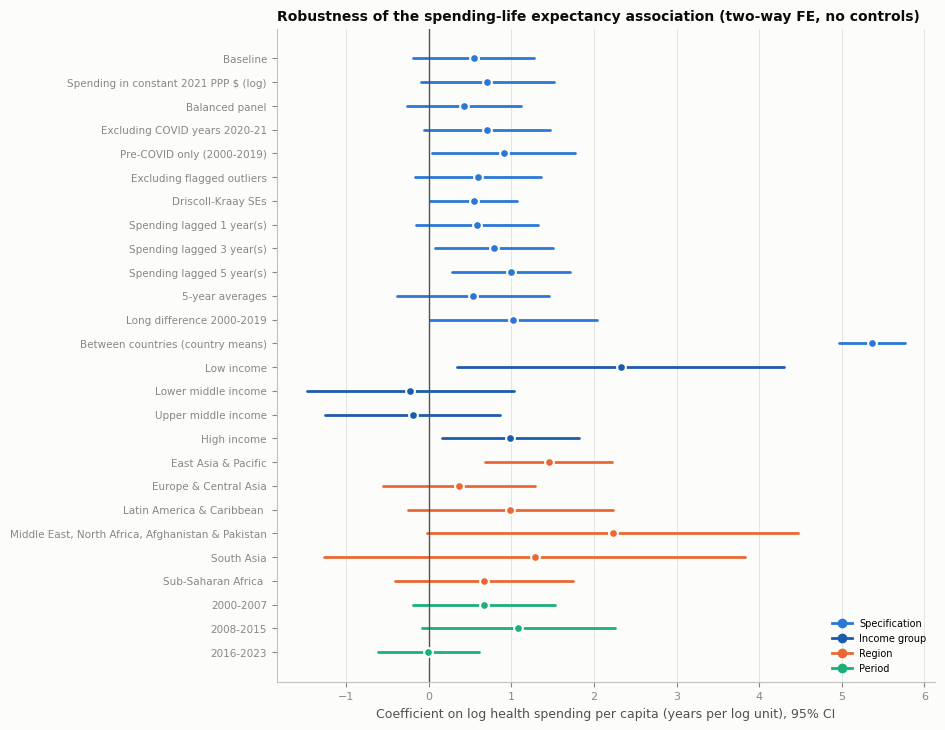

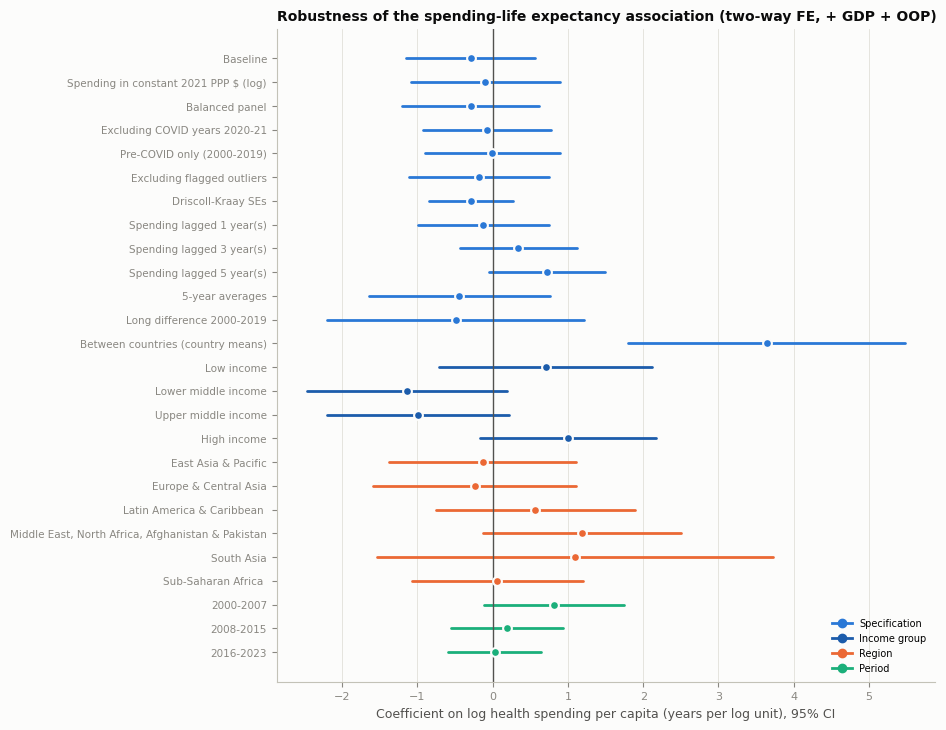

In [34]:
# Forest plot of the spending coefficient across checks
group_colors = {"Specification": SERIES[0], "Income group": INCOME_COLORS["Upper middle income"], "Region": SERIES[1], "Period": SERIES[2]}
for ctrl, fname in [("no controls", "fig09_forest_no_controls.png"), ("+ GDP + OOP", "fig10_forest_full_controls.png")]:
    sub = rob[(rob.controls == ctrl) & (rob.group != "Other outcomes")
              & ~rob.model.isin(["Spending as % of GDP", "Spending in current US$ (log)"])].iloc[::-1].reset_index(drop=True)
    fig, ax = plt.subplots(figsize=(8.5, 0.28 * len(sub) + 1.2))
    for i, r in sub.iterrows():
        c = group_colors[r.group]
        ax.plot([r.ci_low, r.ci_high], [i, i], color=c, lw=2, solid_capstyle="round")
        ax.scatter(r.coef, i, s=40, color=c, edgecolor=SURFACE, lw=1.5, zorder=3)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(range(len(sub)), sub.model, fontsize=7.5)
    ax.set_xlabel("Coefficient on log health spending per capita (years per log unit), 95% CI")
    ax.legend(handles=[plt.Line2D([], [], color=c, lw=2, marker="o", label=g) for g, c in group_colors.items()], loc="lower right", fontsize=7)
    ax.set_title(f"Robustness of the spending-life expectancy association (two-way FE, {ctrl})", loc="left", fontsize=10)
    ax.grid(axis="y", visible=False)
    save(fig, fname)

Each row re-estimates the within-country spending coefficient under one alternative choice (Section 6 table). The dot is the estimate, in extra years of life expectancy per log unit of spending (one log unit is about 2.7 times more spending), and the line is its 95% confidence interval. **If the line crosses the vertical zero line, the estimate is not statistically significant at the 5% level.** Colours mark the kind of check.

- **Without controls (first plot)**, almost all estimates are positive, mostly between 0.5 and 1.0 years, but most intervals touch zero. Only 9 of 26 clear it: pre-COVID only, Driscoll-Kraay errors, 3- and 5-year lags, the long difference, the low- and high-income groups, East Asia & Pacific, and the between-country estimate.
- **With GDP and out-of-pocket share (second plot)**, the estimates gather around zero and **only the between-country estimate clears zero** (3.6 years).
- **The between-country row sits far to the right in both plots** (5.4 and 3.6). Comparing different countries shows a much stronger association than following one country over time, the main finding of Section 5.
- **Subgroup intervals are wide** because each contains few countries; South Asia has only six.

### Did the relationship change over time? (period interaction test)

Here the spending slope is allowed to differ by period. The rows for 2008–2015 and 2016–2023 show how much the slope changed compared with 2000–2007.

In [35]:
di = df.copy()
for p in ["2008-2015", "2016-2023"]:
    di[f"che_x_{p}"] = di[SPEND] * (di.period == p)
res_int = fit_panel(di, Y, [SPEND, "che_x_2008-2015", "che_x_2016-2023", *BASE_X])
pint = pd.DataFrame({"coef": res_int.params, "se": res_int.std_errors, "p": res_int.pvalues})
pint.to_csv(TABLE_DIR / "robustness_period_interaction.csv")
pint.round(3)

,coef,se,p
log_che_pc_ppp,0.373,0.413,0.366
che_x_2008-2015,-0.426,0.105,0.000
che_x_2016-2023,-0.976,0.163,0.000
log_gdp_pc_ppp,1.303,0.698,0.062
oop_10,-0.170,0.111,0.125


### Why did the relationship weaken? (finer periods)

Two explanations are possible. One is COVID-19. The other is diminishing returns: spending is higher in later years, and the curve is flatter at high spending. We split 2016–2023 into 2016–2019 (before COVID), 2020–2021 (COVID) and 2022–2023 (after), and fit the model with and without the squared spending term. If the decline disappears once the squared term is included, diminishing returns explain it.

In [36]:
# Finer periods (2000-2007 is the reference), with and without the squared spending term
SUBPERIODS = {"2008-2015": (2008, 2015), "2016-2019": (2016, 2019), "2020-2021": (2020, 2021), "2022-2023": (2022, 2023)}
ds = df.copy()
for p, (y0, y1) in SUBPERIODS.items():
    ds[f"che_x_{p}"] = ds["log_che_c"] * ds["year"].between(y0, y1)
inter = [f"che_x_{p}" for p in SUBPERIODS]

sub = {}
for lab, extra in [("without squared term", []), ("with squared term", ["log_che_c_sq"])]:
    res = fit_panel(ds, Y, ["log_che_c", *inter, *extra, *BASE_X])
    sub[lab] = {t: f"{res.params[t]:.3f}{stars(res.pvalues[t])} (p={res.pvalues[t]:.3f})" for t in ["log_che_c", *inter, *extra]}
sub = pd.DataFrame(sub)
sub.to_csv(TABLE_DIR / "robustness_subperiod_interaction.csv")
med_spend = df.groupby(pd.cut(df.year, [1999, 2007, 2015, 2019, 2021, 2023],
                              labels=["2000-2007", *SUBPERIODS]), observed=True)["che_pc_ppp"].median()
display(Markdown("**Median health spending per capita (PPP $) by period**"), med_spend.round(0).to_frame().T)
sub

**Median health spending per capita (PPP $) by period**

year,2000-2007,2008-2015,2016-2019,2020-2021,2022-2023
che_pc_ppp,376.000,603.000,772.000,934.000,"1,111.000"


,without squared term,with squared term
log_che_c,0.402 (p=0.329),-0.460 (p=0.322)
che_x_2008-2015,-0.423*** (p=0.000),-0.122 (p=0.287)
che_x_2016-2019,-0.761*** (p=0.000),-0.288 (p=0.131)
che_x_2020-2021,-1.088*** (p=0.000),-0.481** (p=0.025)
che_x_2022-2023,-1.281*** (p=0.000),-0.614*** (p=0.006)
log_che_c_sq,NaN,-0.356*** (p=0.001)


- **Without the squared term,** the slope falls period by period, from −0.42 in 2008–2015 to −1.28 in 2022–2023 (all p < 0.001). The decline had already started **before COVID**.
- Over the same periods, median spending rose from $376 to $1,111, so later years sit on the flatter part of the curve.
- **With the squared term,** the 2008–2015 and 2016–2019 changes become small and not significant. What remains is in **2020–2021 (−0.48, p = 0.03)** and **2022–2023 (−0.61, p = 0.006)**.
- **Conclusion:** much of the weakening is explained by diminishing returns. The remaining drop is concentrated in the COVID and post-COVID years, when spending rose while life expectancy fell and then recovered. This is an association; the data cannot separate COVID from other changes in those years.

### Current vs constant prices

Spending is measured in current international dollars, which include inflation, while GDP is in constant 2021 dollars. We rebuilt spending in constant 2021 dollars as (spending share of GDP) × (constant GDP) and re-estimated the key models.

In [37]:
# Current-$ spending vs spending rebuilt in constant 2021 PPP $ (share of GDP x constant GDP)
rows = []
for var, lab, data in [("log_che_pc_ppp", "current intl $ (main)", df), ("log_che_const", "constant 2021 intl $", df),
                       ("log_che_pc_ppp", "current intl $, excluding 2020-21", df[~df.covid])]:
    c = data[var] - data[var].mean()
    nlq = fit_panel(data.assign(c=c, c_sq=c ** 2), Y, ["c", "c_sq", *BASE_X])
    row = {"spending measure / sample": lab}
    for name, xs, kw in [("(1) pooled", [var], dict(pooled=True)), ("(2) country FE", [var], dict(time=False)),
                         ("(3) two-way FE", [var], {}), ("(5) + GDP + OOP", [var, *BASE_X], {})]:
        r = fit_panel(data, Y, xs, **kw)
        row[name] = f"{r.params[var]:.3f}{stars(r.pvalues[var])}"
    row["turning point ($)"] = round(float(np.exp(data[var].mean() - nlq.params["c"] / (2 * nlq.params["c_sq"]))))
    rows.append(row)
prices = pd.DataFrame(rows).set_index("spending measure / sample")
prices.to_csv(TABLE_DIR / "robustness_current_vs_constant_prices.csv")
print(f"Correlation of the two log spending measures: {df[['log_che_pc_ppp', 'log_che_const']].corr().iloc[0, 1]:.3f}")
prices

Correlation of the two log spending measures: 0.988


,(1) pooled,(2) country FE,(3) two-way FE,(5) + GDP + OOP,turning point ($)
spending measure / sample,,,,,
current intl $ (main),5.216***,3.823***,0.543,-0.294,220
constant 2021 intl $,5.315***,4.742***,0.710*,-0.100,294
"current intl $, excluding 2020-21",5.290***,4.165***,0.704*,-0.072,249


- The two spending measures are almost identical (correlation 0.988).
- As expected, the models with year fixed effects barely change, because inflation common to all countries is absorbed by the year effects: model (3) gives 0.54 vs 0.71 (p = 0.08), and model (5) −0.29 vs −0.10, both not significant.
- The country-FE model without year effects rises from 3.8 to 4.7, and the turning point moves from $220 to about $290.
- Without the COVID years 2020–21 (last row), the turning point is about $250.
- **Conclusion:** no finding changes, but the turning point should be read as approximate.

**Robustness summary**

- **Robust:**
  - The **cross-country association** stays large and highly significant after controlling for GDP and out-of-pocket share (between estimator: 5.37 without and 3.64 with controls, both p < 0.001).
  - **Same-year spending within a country** is not significantly associated with life expectancy once GDP and the out-of-pocket share are controlled for, in every specification check. A few subgroup splits are marginal at the 10% level (lower-middle income, high income, Middle East and North Africa, and 2000–2007), with mixed signs, so they do not change the overall picture.
  - **Delayed spending:** spending lagged five years shows a positive within-country association (0.99, p = 0.007; 0.72 with controls, p = 0.07).
- **Depends on choices:** the within-country estimate *without controls* (0.54) is not significant with country-clustered errors (p = 0.15), but it is with Driscoll-Kraay errors (p = 0.04), in the pre-COVID sample (0.91, p = 0.04) and, at the 10% level, with constant-price spending (0.71, p = 0.08).
- **Heterogeneity:**
  - Without controls, within-country associations are positive in low-income (2.33, p = 0.02) and high-income countries (0.99, p = 0.02), and about zero in middle-income countries. With controls, the high-income estimate stays marginal (1.00, p = 0.10), and the lower-middle estimate turns negative (−1.14, p = 0.09).
  - The association **weakened over time** (2016–2023 interaction −0.98, p < 0.001). Much of this is diminishing returns; the rest is concentrated in 2020–2023.
- **Other outcomes:** 10% more spending ↔ about 1.7% lower under-5 mortality and about 1.4% lower maternal mortality (both p < 0.01). Both become insignificant once GDP is controlled for.

## 7. Statistical inference: out-of-pocket burden

Do countries that rely more on **direct patient payments** have different outcomes?

- **Groups:** countries are split at the median out-of-pocket share (2016–2023 country averages).
- **Permutation test** (10,000 shuffles): is the observed difference larger than what random group labels would produce?
- **Bootstrap** (5,000 resamples): 95% confidence intervals for the difference.

Because poorer countries rely more on out-of-pocket payments, the comparison is also made **adjusted for GDP** and **within income groups**.

In [38]:
N_PERM, N_BOOT = 10_000, 5_000
cs = (df[df.year >= 2016].groupby(["iso3", "country", "income_group", "region"], as_index=False)
        [["life_exp", "che_pc_ppp", "log_che_pc_ppp", "oop_pct_che", "log_gdp_pc_ppp", "u5_mort"]].mean())
median_oop = cs.oop_pct_che.median()
cs["high_oop"] = cs.oop_pct_che >= median_oop
cs["le_resid_gdp"] = smf.ols("life_exp ~ log_gdp_pc_ppp", cs).fit().resid    # LE adjusted for national income
cs["le_resid_che"] = smf.ols("life_exp ~ log_che_pc_ppp", cs).fit().resid    # LE adjusted for spending
print(f"{len(cs)} countries; median out-of-pocket share 2016-2023 = {median_oop:.1f}%")

def perm_test(values, groups, strata=None, n=N_PERM):
    # Two-sided permutation test for a difference in means (high - low); optionally shuffle labels within strata
    values, groups = np.asarray(values), np.asarray(groups)
    obs = values[groups].mean() - values[~groups].mean()
    diffs = np.empty(n)
    for i in range(n):
        g = groups.copy()
        if strata is None:
            g = rng.permutation(g)
        else:
            for s in np.unique(strata):
                idx = np.where(strata == s)[0]
                g[idx] = rng.permutation(groups[idx])
        diffs[i] = values[g].mean() - values[~g].mean()
    return obs, (np.sum(np.abs(diffs) >= abs(obs)) + 1) / (n + 1), diffs

def boot_diff(values, groups, n=N_BOOT):
    # Percentile bootstrap 95% CI for a difference in means
    a, b = np.asarray(values)[groups], np.asarray(values)[~groups]
    d = [rng.choice(a, len(a)).mean() - rng.choice(b, len(b)).mean() for _ in range(n)]
    return np.percentile(d, [2.5, 97.5])

186 countries; median out-of-pocket share 2016-2023 = 28.7%


In [39]:
tests = []
for label, col, strata in [("Life expectancy (raw)", "life_exp", None),
                           ("Life expectancy adjusted for GDP", "le_resid_gdp", None),
                           ("Life expectancy adjusted for spending", "le_resid_che", None),
                           ("Life expectancy, labels permuted within income group", "life_exp", cs.income_group.values),
                           ("Under-5 mortality (raw)", "u5_mort", None)]:
    obs, p, diffs = perm_test(cs[col].values, cs.high_oop.values, strata)
    # The within-income-group row only changes the p-value; its gap is the raw gap, so no separate CI is shown
    lo, hi = boot_diff(cs[col].values, cs.high_oop.values) if strata is None else (np.nan, np.nan)
    tests.append({"comparison (high OOP - low OOP)": label, "difference": obs, "boot 95% CI low": lo, "boot 95% CI high": hi, "permutation p": p})
    if label == "Life expectancy (raw)":
        raw_obs, raw_diffs = obs, diffs
tests = pd.DataFrame(tests)
tests.to_csv(TABLE_DIR / "inference_oop_permutation_tests.csv", index=False)
tests.round(3)

,comparison (high OOP - low OOP),difference,boot 95% CI low,boot 95% CI high,permutation p
0,Life expectancy (raw),-4.144,-6.251,-2.059,0.000
1,Life expectancy adjusted for GDP,0.059,-1.001,1.147,0.917
2,Life expectancy adjusted for spending,0.424,-0.672,1.523,0.454
3,"Life expectancy, labels permuted within income...",-4.144,NaN,NaN,0.690
4,Under-5 mortality (raw),17.458,9.631,25.536,0.000


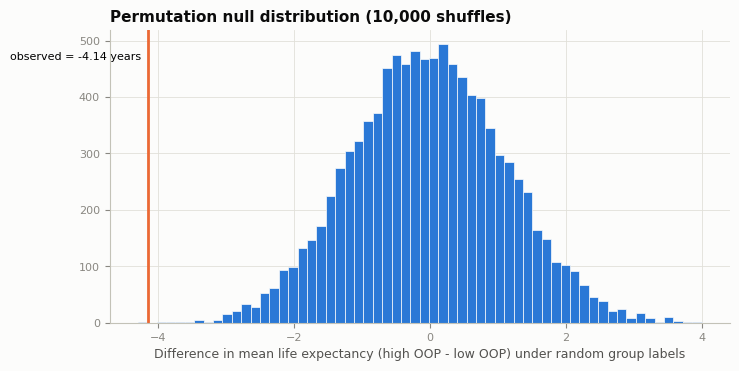

In [40]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(raw_diffs, bins=60, color=SERIES[0], edgecolor=SURFACE, lw=0.5)
ax.axvline(raw_obs, color=SERIES[1], lw=2)
ax.text(raw_obs, ax.get_ylim()[1] * 0.9, f"observed = {raw_obs:.2f} years  ", ha="right", fontsize=8)
ax.set_xlabel("Difference in mean life expectancy (high OOP - low OOP) under random group labels")
ax.set_title(f"Permutation null distribution ({N_PERM:,} shuffles)", loc="left")
save(fig, "fig11_permutation_oop.png")

The blue histogram shows the gap in life expectancy we would see if the "high" and "low" out-of-pocket labels were handed out at random, repeated 10,000 times. It is centred on zero and almost never goes beyond ±3.5 years. The orange line is the actual gap (−4.14 years). It lies further left than every shuffled result, so chance alone is very unlikely to produce a gap this large.

Countries with a high out-of-pocket burden live **4.1 years less** on average (permutation p < 0.001). That gap **disappears after adjusting for GDP** (+0.06 years, p = 0.92), and it is not significant when labels are shuffled within income groups (p = 0.69). The raw gap therefore mostly reflects the fact that poorer countries rely more on direct payments.

*Note on the table:* the within-income-group row shows no confidence interval. Its gap is the same raw gap as in the first row; only the way the p-value is computed changes, so a separate interval would be misleading.

**Within each income group:**

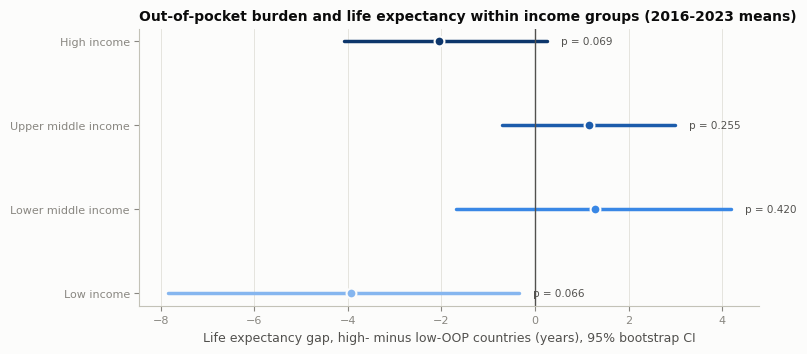

,income_group,n,median_oop,LE gap (high-low OOP),CI low,CI high,permutation p
0,Low income,21,40.474,-3.930,-7.850,-0.334,0.066
1,Lower middle income,46,38.293,1.278,-1.698,4.194,0.420
2,Upper middle income,57,33.313,1.145,-0.711,2.989,0.255
3,High income,62,18.526,-2.062,-4.090,0.254,0.069


In [41]:
within = []
for g in INCOME_ORDER:
    s = cs[cs.income_group == g]
    hi_grp = (s.oop_pct_che >= s.oop_pct_che.median()).values
    obs, p, _ = perm_test(s.life_exp.values, hi_grp)
    lo, hi = boot_diff(s.life_exp.values, hi_grp)
    within.append({"income_group": g, "n": len(s), "median_oop": s.oop_pct_che.median(), "LE gap (high-low OOP)": obs,
                   "CI low": lo, "CI high": hi, "permutation p": p})
within = pd.DataFrame(within)
within.to_csv(TABLE_DIR / "inference_oop_within_income.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.6))
for i, r in within.iterrows():
    c = INCOME_COLORS[r.income_group]
    ax.plot([r["CI low"], r["CI high"]], [i, i], color=c, lw=2.5, solid_capstyle="round")
    ax.scatter(r["LE gap (high-low OOP)"], i, s=50, color=c, edgecolor=SURFACE, lw=1.5, zorder=3)
    ax.text(r["CI high"] + 0.3, i, f"p = {r['permutation p']:.3f}", va="center", fontsize=7.5, color=INK2)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(range(len(within)), within.income_group)
ax.set_xlabel("Life expectancy gap, high- minus low-OOP countries (years), 95% bootstrap CI")
ax.set_title("Out-of-pocket burden and life expectancy within income groups (2016-2023 means)", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
save(fig, "fig13_oop_gap_by_income.png")
within.round(3)

Within income groups the gap is negative for **low-income** countries (−3.9 years, p = 0.07) and **high-income** countries (−2.1 years, p = 0.07), and not significant for the middle-income groups.

**Are these gaps driven by one country?** Each group has few countries (only 21 are low income), so a single country can move the average. We recompute each gap leaving out one country at a time, and once more without flagged country-years (Section 3.7).

In [42]:
# How much does a single country, or a flagged record, drive each within-group gap?
def oop_gap(d):
    # Life expectancy gap, high- minus low-OOP countries, splitting at the group's own median OOP share
    hi_grp = d.oop_pct_che >= d.oop_pct_che.median()
    return d.life_exp[hi_grp].mean() - d.life_exp[~hi_grp].mean()

cs_clean = (df[(df.year >= 2016) & ~df.flag_outlier].groupby(["iso3", "country", "income_group"], as_index=False)
              [["life_exp", "oop_pct_che"]].mean())          # 2016-2023 means without flagged country-years
sens = []
for g in INCOME_ORDER:
    s = cs[cs.income_group == g]
    loo = pd.Series({c: oop_gap(s[s.country != c]) for c in s.country})
    sens.append({"income_group": g, "gap (all countries)": oop_gap(s),
                 "lowest gap leaving one country out": loo.min(), "country left out (lowest)": loo.idxmin(),
                 "highest gap leaving one country out": loo.max(), "country left out (highest)": loo.idxmax(),
                 "gap without flagged country-years": oop_gap(cs_clean[cs_clean.income_group == g])})
sens = pd.DataFrame(sens)
sens.to_csv(TABLE_DIR / "inference_oop_within_income_sensitivity.csv", index=False)
sens.round(2)

,income_group,gap (all countries),lowest gap leaving one country out,country left out (lowest),highest gap leaving one country out,country left out (highest),gap without flagged country-years
0,Low income,-3.930,-4.920,Syrian Arab Republic,-2.660,Central African Republic,-3.530
1,Lower middle income,1.280,0.780,Lesotho,2.660,Nigeria,1.340
2,Upper middle income,1.140,0.950,Albania,1.610,Maldives,1.100
3,High income,-2.060,-2.680,Nauru,-1.590,Guyana,-2.030


- **Low income:** the gap ranges from −4.9 to −2.7 years depending on which country is left out. Leaving out the Central African Republic gives the weakest gap (−2.7, closest to zero). Without flagged country-years it is −3.5.
- **High income:** −2.7 to −1.6 years; without flagged country-years −2.0.
- The direction is stable, but the size depends on single countries, and with p ≈ 0.07 the evidence is weak. **We treat this as an exploratory pattern, not a finding.**

**Possible explanations (hypotheses, not tested here):**

- In low-income countries, high direct payments may stop people from seeking care, or reflect weak public health systems.
- In high-income countries, a higher out-of-pocket share may reflect gaps in insurance coverage for some groups.
- In both, the out-of-pocket share may stand in for other differences we do not measure, such as governance or inequality.

Testing these would need household-level data on access to care and financial hardship.

### Bootstrap confidence intervals by income group, and a country-cluster bootstrap

In [43]:
grp = []
for g in INCOME_ORDER:
    s = cs[cs.income_group == g]
    means = [rng.choice(s.life_exp.values, len(s)).mean() for _ in range(N_BOOT)]
    slopes = []
    for _ in range(2000):
        bs = s.sample(len(s), replace=True, random_state=int(rng.integers(1e9)))
        slopes.append(np.polyfit(bs.log_che_pc_ppp, bs.life_exp, 1)[0])
    grp.append({"income_group": g, "n": len(s), "mean LE": s.life_exp.mean(),
                "LE CI": f"[{np.percentile(means, 2.5):.1f}, {np.percentile(means, 97.5):.1f}]",
                "slope LE~log CHE": np.polyfit(s.log_che_pc_ppp, s.life_exp, 1)[0],
                "slope CI": f"[{np.percentile(slopes, 2.5):.2f}, {np.percentile(slopes, 97.5):.2f}]"})
grp = pd.DataFrame(grp)
grp.to_csv(TABLE_DIR / "inference_bootstrap_by_income.csv", index=False)
display(grp.round(2))

# Country-cluster bootstrap of model (5): resample whole countries with replacement
ids, by_id = df.iso3.unique(), dict(tuple(df.groupby("iso3")))
N_CLUSTER_BOOT = 2000          # each resample refits the panel model, so this is slower than the other bootstraps
boot_b = []
for _ in range(N_CLUSTER_BOOT):
    pick = rng.choice(ids, len(ids), replace=True)
    bs = pd.concat([by_id[c].assign(iso3=f"{c}_{j}") for j, c in enumerate(pick)])
    boot_b.append(fit_panel(bs, Y, ["log_che_pc_ppp", "log_gdp_pc_ppp", "oop_10"], cov="unadjusted")
                  .params[["log_che_pc_ppp", "log_gdp_pc_ppp", "oop_10"]].values)
boot_b = np.array(boot_b)
cluster_ci = pd.DataFrame({"term": ["log_che_pc_ppp", "log_gdp_pc_ppp", "oop_10"], "bootstrap mean": boot_b.mean(0),
                           "CI low": np.percentile(boot_b, 2.5, 0), "CI high": np.percentile(boot_b, 97.5, 0)})
cluster_ci.to_csv(TABLE_DIR / "inference_cluster_bootstrap_twfe.csv", index=False)
print(f"Country-cluster bootstrap ({N_CLUSTER_BOOT:,} resamples) of model (5):")
cluster_ci.round(3)

,income_group,n,mean LE,LE CI,slope LE~log CHE,slope CI
0,Low income,21,61.450,"[59.2, 63.4]",2.950,"[0.32, 6.91]"
1,Lower middle income,46,66.600,"[65.1, 68.0]",3.500,"[1.11, 5.86]"
2,Upper middle income,57,72.690,"[71.7, 73.6]",3.680,"[2.09, 5.39]"
3,High income,62,79.030,"[77.9, 80.1]",5.600,"[3.94, 7.60]"


Country-cluster bootstrap (2,000 resamples) of model (5):


,term,bootstrap mean,CI low,CI high
0,log_che_pc_ppp,-0.295,-1.090,0.525
1,log_gdp_pc_ppp,2.135,0.717,3.503
2,oop_10,-0.255,-0.506,-0.013


- Within every income group, countries that spend more live longer (2016–2023 country means). The slope is largest in high-income countries (5.6).
- The country-cluster bootstrap agrees with model (5): the spending interval includes zero (−1.09 to 0.53), GDP is clearly positive (0.72 to 3.50), and the out-of-pocket interval is −0.51 to −0.01. Its upper end is essentially zero and moves with the random draws, so together with p = 0.05 in model (5) this is borderline evidence, not a firm result.

### Visualizing the Relationship Between Out-of-Pocket Expenditure and Life Expectancy

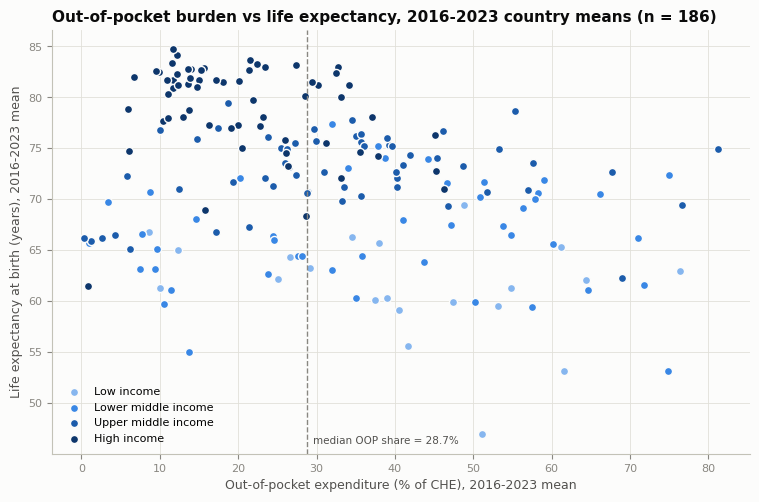

In [44]:
# Out-of-pocket share vs life expectancy, 2016-2023 country means (the data used in the tests above)
fig, ax = plt.subplots(figsize=(9, 5.5))
for g in INCOME_ORDER:
    s = cs[cs.income_group == g]
    ax.scatter(s.oop_pct_che, s.life_exp, s=34, color=INCOME_COLORS[g], label=g, edgecolor=SURFACE, linewidth=1)
ax.axvline(median_oop, color=MUTED, lw=1, ls="--")
ax.text(median_oop + 0.8, ax.get_ylim()[0] + 1, f"median OOP share = {median_oop:.1f}%", fontsize=7.5, color=INK2)
ax.set_xlabel(LABELS["oop_pct_che"] + ", 2016-2023 mean")
ax.set_ylabel(LABELS["life_exp"] + ", 2016-2023 mean")
ax.set_title(f"Out-of-pocket burden vs life expectancy, 2016-2023 country means (n = {len(cs)})", loc="left")
ax.legend(loc="lower left")
save(fig, "fig14_oop_vs_life_exp_2016_2023.png")

Each point is one country's 2016–2023 average; the dashed line is the median split used in the tests above. The colours show why the raw gap shrinks after adjustment: high-income countries (dark blue) cluster at low out-of-pocket shares and high life expectancy, and low-income countries at higher shares and lower life expectancy. Within a single income group the pattern is weaker and mixed in direction, matching the within-group results that follow.

## 8. Which countries perform better or worse than expected?

A cross-sectional line, life expectancy on log spending, is fitted for the latest year. Each country's **residual** is its life expectancy minus the value expected for its spending level.

*Why a straight line rather than a curve?* Adding a squared term hardly improves the fit (R² 0.721 vs 0.715) and is not significant at the 5% level (p = 0.057). It also bends **upward**, so at US spending it would expect 86.3 years, more than any country actually reaches (the maximum is 85.7). That would exaggerate the US gap. A straight line in *log* spending already implies that each extra year of life expectancy goes with a larger dollar increase in spending.

In [45]:
lat = df[df.year == LATEST].copy()
# Expected life expectancy = straight line in log spending (see the note above for why not a parabola)
m_spend = smf.ols("life_exp ~ log_che_pc_ppp", lat).fit()
m_full = smf.ols("life_exp ~ log_che_pc_ppp + log_gdp_pc_ppp + oop_pct_che", lat).fit()
lat["expected_le"], lat["residual"], lat["residual_full"] = m_spend.fittedvalues, m_spend.resid, m_full.resid
lat["rank"] = lat.residual.rank(ascending=False).astype(int)

# Check of the alternative: adding a squared term
m_quad = smf.ols("life_exp ~ log_che_pc_ppp + I(log_che_pc_ppp**2)", lat).fit()
us_quad = m_quad.predict(lat[lat.iso3 == "USA"]).item()
print(f"Squared-term check: coefficient {m_quad.params.iloc[2]:+.3f} (p = {m_quad.pvalues.iloc[2]:.3f}), "
      f"R² {m_quad.rsquared:.3f} vs {m_spend.rsquared:.3f} for the straight line; it would expect {us_quad:.1f} years "
      f"for the US, above the highest life expectancy observed in any country ({lat.life_exp.max():.1f}).")

perf = lat[["iso3", "country", "income_group", "che_pc_ppp", "oop_pct_che", "life_exp", "expected_le", "residual",
            "residual_full", "rank"]].sort_values("residual", ascending=False)
perf.to_csv(TABLE_DIR / "performance_vs_expected.csv", index=False)
print(f"R² = {m_spend.rsquared:.3f} (spending only), {m_full.rsquared:.3f} (+ GDP, OOP); {len(perf)} countries; "
      f"+1 log unit of spending ↔ {m_spend.params['log_che_pc_ppp']:.2f} years")
show_cols = ["country", "che_pc_ppp", "life_exp", "expected_le", "residual", "rank"]
display(Markdown("**Top 10 over-performers**"), perf.head(10)[show_cols].round(1))
display(Markdown("**Top 10 under-performers**"), perf.tail(10)[show_cols].round(1))
display(Markdown("**France and the United States**"), perf[perf.iso3.isin(HIGHLIGHT)][show_cols + ["residual_full"]].round(2))

Squared-term check: coefficient +0.272 (p = 0.057), R² 0.721 vs 0.715 for the straight line; it would expect 86.3 years for the US, above the highest life expectancy observed in any country (85.7).
R² = 0.715 (spending only), 0.756 (+ GDP, OOP); 184 countries; +1 log unit of spending ↔ 4.43 years


**Top 10 over-performers**

,country,che_pc_ppp,life_exp,expected_le,residual,rank
4391,Sudan,28.300,66.300,57.400,8.900,1
465,Bangladesh,198.500,74.700,66.100,8.600,2
2961,Sri Lanka,507.100,77.500,70.200,7.300,3
5483,Vanuatu,141.200,71.500,64.600,6.900,4
2831,Lebanon,643.800,77.800,71.300,6.500,5
2779,Kuwait,"2,566.800",83.200,77.400,5.800,6
4469,Solomon Islands,153.400,70.500,64.900,5.600,7
2545,Jordan,797.800,77.800,72.200,5.600,8
3897,Oman,"1,444.400",80.000,74.900,5.200,9
4547,San Marino,"5,231.100",85.700,80.600,5.200,10


**Top 10 under-performers**

,country,che_pc_ppp,life_exp,expected_le,residual,rank
4027,Palau,"1,856.700",69.300,76.000,-6.700,175
829,Central African Republic,136.700,57.400,64.400,-7.000,176
1973,Equatorial Guinea,609.300,63.700,71.000,-7.300,177
5171,Tuvalu,"1,670.900",67.100,75.500,-8.400,178
5587,South Africa,"1,353.800",66.100,74.600,-8.400,179
4781,Eswatini,922.000,64.100,72.900,-8.700,180
4911,Chad,129.900,55.100,64.200,-9.100,181
2987,Lesotho,385.600,57.400,69.000,-11.600,182
3715,Nigeria,260.100,54.500,67.300,-12.800,183
3845,Nauru,"2,474.200",62.100,77.200,-15.100,184


**France and the United States**

,country,che_pc_ppp,life_exp,expected_le,residual,rank,residual_full
1687,France,"6,719.080",82.830,81.660,1.170,73,1.950
5301,United States,"13,473.190",78.390,84.740,-6.350,174,-4.720


### How model-dependent is the US gap?

The "expected" life expectancy depends on which countries and variables the model uses. We compare three reasonable models, plus a simple comparison with the high-income median.

In [46]:
# The US gap under several reasonable definitions of "expected" life expectancy
hi_lat = lat[lat.income_group == "High income"].copy()
m_hi = smf.ols("life_exp ~ log_che_pc_ppp", hi_lat).fit()
hi_lat["residual_hi"] = m_hi.resid
hi_median_le = hi_lat.life_exp.median()

models = {"spending line, all countries": (lat, "residual"),
          "+ GDP + OOP, all countries": (lat, "residual_full"),
          "spending line, high-income countries only": (hi_lat, "residual_hi")}
comp = []
for label, (d, col) in models.items():
    rank = d[col].rank(ascending=False)
    row = {"model": label, "countries": len(d)}
    for iso, name in HIGHLIGHT.items():
        i = d.index[d.iso3 == iso][0]
        row[f"{name}: years vs expected"], row[f"{name}: rank"] = d.at[i, col], int(rank[i])
    comp.append(row)

def peer_gap(iso, k=10):
    # Life expectancy minus the mean of the k countries whose spending is closest (no model, no extrapolation)
    r = lat[lat.iso3 == iso].iloc[0]
    others = lat[lat.iso3 != iso]
    near = others.loc[(others.log_che_pc_ppp - r.log_che_pc_ppp).abs().nsmallest(k).index]
    return r.life_exp - near.life_exp.mean()

comp.append({"model": "minus the 10 countries with the closest spending", "countries": 10,
             **{f"{name}: years vs expected": peer_gap(iso) for iso, name in HIGHLIGHT.items()}})
comp.append({"model": "minus the high-income median", "countries": len(hi_lat),
             **{f"{name}: years vs expected": lat.loc[lat.iso3 == iso, "life_exp"].item() - hi_median_le
                for iso, name in HIGHLIGHT.items()}})
us_models = pd.DataFrame(comp).set_index("model")
for col in [c for c in us_models.columns if c.endswith("rank")]:
    us_models[col] = us_models[col].astype("Int64")   # whole numbers; blank where a rank does not apply
us_models.to_csv(TABLE_DIR / "performance_us_model_comparison.csv")
display(us_models.round(2))

# Has the US gap changed over time? (same all-country spending line, refitted each year)
us_trend = {}
for y in [2000, 2005, 2010, 2015, 2019, LATEST]:
    d = df[df.year == y]
    us_trend[y] = d.loc[d.iso3 == "USA", "life_exp"].item() - smf.ols("life_exp ~ log_che_pc_ppp", d).fit().predict(d[d.iso3 == "USA"]).item()
print("US gap vs the spending line, by year: " + ", ".join(f"{y}: {v:+.1f}" for y, v in us_trend.items()))

,countries,France: years vs expected,France: rank,United States: years vs expected,United States: rank
model,,,,,
"spending line, all countries",184,1.170,73,-6.350,174
"+ GDP + OOP, all countries",184,1.950,56,-4.720,169
"spending line, high-income countries only",62,0.680,24,-7.050,61
minus the 10 countries with the closest spending,10,0.590,<NA>,-4.290,<NA>
minus the high-income median,62,1.400,<NA>,-3.050,<NA>


US gap vs the spending line, by year: 2000: -5.6, 2005: -6.7, 2010: -6.2, 2015: -6.6, 2019: -6.6, 2023: -6.4


- **United States:** −6.4 years against the all-country spending line, −4.7 with GDP and out-of-pocket share added, −7.1 among high-income countries only, −4.3 compared with the ten countries whose spending is closest to its own (Switzerland, Norway, Luxembourg, Germany and others), and −3.1 compared with the high-income median. In the three models it ranks near the bottom (169–174 of 184; 61 of 62 high-income countries).
- The two simple comparisons (closest spenders, high-income median) need no fitted line, so they do not extend a line beyond the data; they give the smallest gaps. We therefore report the US gap as **about 3 to 7 years below expectation**, depending on the comparison, rather than a single number.
- **The gap is not new:** against the same line it was −5.6 years in 2000 and has stayed between −6.2 and −6.7 since 2005.
- **France** is above expectation in every version (+0.6 to +2.0 years).

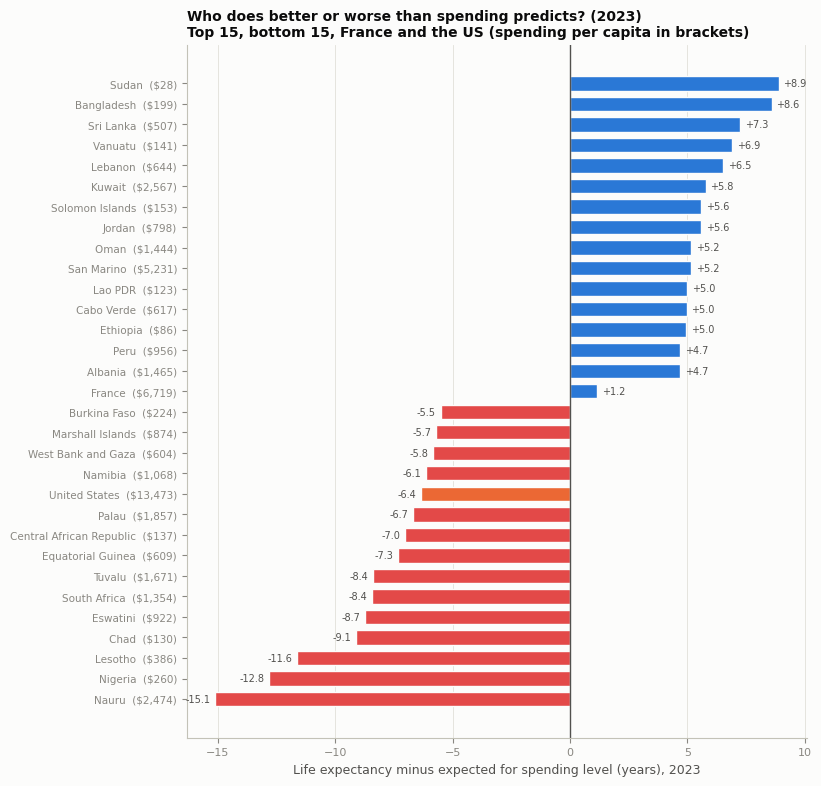

In [47]:
show = pd.concat([perf.head(15), perf[perf.iso3.isin(HIGHLIGHT)], perf.tail(15)]).drop_duplicates("iso3").sort_values("residual")
fig, ax = plt.subplots(figsize=(8, 9))
colors = [COUNTRY_COLORS.get(i, SERIES[0] if r > 0 else SERIES[7]) for i, r in zip(show.iso3, show.residual)]
ax.barh(range(len(show)), show.residual, color=colors, height=0.7, edgecolor=SURFACE, lw=1)
ax.set_yticks(range(len(show)), [f"{c}  (${s:,.0f})" for c, s in zip(show.country, show.che_pc_ppp)], fontsize=7.5)
ax.axvline(0, color=INK2, lw=1)
for i, v in enumerate(show.residual):
    ax.text(v + (0.2 if v > 0 else -0.2), i, f"{v:+.1f}", va="center", ha="left" if v > 0 else "right", fontsize=7, color=INK2)
ax.set_xlabel(f"Life expectancy minus expected for spending level (years), {LATEST}")
ax.set_title(f"Who does better or worse than spending predicts? ({LATEST})\nTop 15, bottom 15, France and the US (spending per capita in brackets)",
             loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
save(fig, "fig12_over_under_performers.png")

- **Over-performers** include Sudan, Bangladesh, Sri Lanka, Vanuatu, Lebanon, Jordan and Peru: they reach a higher life expectancy than their spending predicts. Sudan's +8.9 should be read with caution, because it has the lowest spending in the sample ($28 per person) and its 2023 values are estimates for a year of civil war.
- **Under-performers** include Nauru, Nigeria, Lesotho, Chad, Eswatini and South Africa, where HIV/AIDS, conflict or small-island data issues play a role, and the **United States**, about 3–7 years below expectation depending on the comparison.
- **France** is slightly above expectation.
- *Caveats:* a positive residual does not prove good performance, because the model includes only spending (or spending, GDP and out-of-pocket share), and other factors can explain a gap. The US spends more than any other country, so any fitted line has to be extended beyond the data to give its "expected" value; the comparisons with the closest spenders and with the high-income median avoid this.

## 9. Interactive dashboard

The proposal includes an interactive dashboard for exploring countries, regions, indicators and years. The cell below builds it as a single HTML file: it packs the processed data into JSON and inserts it, together with the Plotly charting library and the world-map shapes (both in `assets/`), into the page layout stored in `dashboard_template.html`.

Records that failed the validity checks (Section 3.4) are left out, as in the analysis.

**To view it:** open `outputs/dashboard.html` in any web browser. The charting library is built into the file, so it works **without internet**. It includes:
- a choropleth map with an indicator selector and year slider;
- a spending-vs-outcome scatter with selectable axes;
- trend lines for selected countries;
- a sortable country table.

In [48]:
dash_vars = ["life_exp", "che_pc_ppp", "che_pct_gdp", "oop_pct_che", "gov_pct_che", "gdp_pc_ppp", "u5_mort", "mat_mort"]
d = panel.loc[~panel["flag_invalid"], ["iso3", "country", "region", "income_group", "year", *dash_vars]].copy()   # same exclusion as the analysis
d["income_group"] = d["income_group"].fillna("Not classified")

dash_data = {
    "rows": [[r["iso3"], int(r["year"]), *[None if pd.isna(r[v]) else round(float(r[v]), 2) for v in dash_vars]]
             for _, r in d.iterrows()],
    "vars": dash_vars,
    "labels": {v: LABELS[v] for v in dash_vars},
    "countries": {r.iso3: [r.country, r.region, r.income_group] for r in d.drop_duplicates("iso3").itertuples()},
    "residual": dict(zip(perf.iso3, perf.residual.round(2))),       # life expectancy vs expected (Section 8)
    "logScale": ["che_pc_ppp", "gdp_pc_ppp", "u5_mort", "mat_mort"],
}
template = (ROOT / "dashboard_template.html").read_text()
out = ROOT / "outputs" / "dashboard.html"
plotly_js = (ROOT / "assets" / "plotly-2.35.2.min.js").read_text()      # charting library, bundled so the page works offline
world_map = (ROOT / "assets" / "world_110m.json").read_text()            # map shapes Plotly would otherwise download
out.write_text(template.replace("__DATA__", json.dumps(dash_data, separators=(",", ":")))
                       .replace("__WORLD_TOPOJSON__", world_map)
                       .replace("__PLOTLY_JS__", plotly_js.replace("</script", "<\\/script")))
print(f"Saved {out.relative_to(ROOT)} ({out.stat().st_size / 1e6:.2f} MB)")

Saved outputs/dashboard.html (5.04 MB)


Preview of the dashboard (screenshot):

![Dashboard preview](outputs/figures/dashboard_preview.png)

## 10. Summary and conclusions

### Main findings supported by the analysis

1. **Across countries, higher health spending goes with longer life.** 10% more spending ↔ about **0.5 more years** (pooled 5.22; between-country 5.37, and 3.64 with GDP and out-of-pocket share; all p < 0.001). This compares countries; it is not the effect of one country raising its spending.
2. **Within countries, same-year spending is not associated with life expectancy once global trends and GDP are included** (−0.29, p = 0.50), while GDP is (2.12, p = 0.004).
3. **Returns diminish.** Within-country gains appear only at low spending levels (clearly below about $100 per person; the parabola's turning point is roughly $200–300).
4. **The association weakened over time.** Much of this is diminishing returns as spending rose; the remaining drop is concentrated in 2020–2023.
5. **Out-of-pocket burden.** High-burden countries live about 4.1 years less, but the gap disappears once national income is taken into account (+0.06 years, p = 0.92).
6. **France and the United States.** The US spends about twice as much per person as France ($13,473 vs $6,719 in 2023) but lives 4.4 years less.

### Results that depend on the model or period

- The within-country estimate without controls (0.54) is significant only under some choices (Driscoll-Kraay errors, pre-COVID sample).
- **Delayed spending:** a 5-year lag gives 0.99 (p = 0.007), but only 0.72 (p = 0.07) with controls.
- **Out-of-pocket share in the panel:** −0.25 years per 10 percentage points, borderline (p = 0.05).
- **Turning point:** $220 to about $290, depending on the price measure and on the COVID years.
- **US gap:** about 3 to 7 years below expectation, depending on the comparison (−6.4 years against the all-country spending line).
- **Out-of-pocket gaps within low- and high-income groups:** the direction is stable, but the size depends on single countries such as the Central African Republic.

### Possible explanations requiring further investigation (hypotheses)

- **Negative slope at high spending:** poorer countries caught up faster, so high spenders look as if they gain less than the global trend.
- **Recent weakening:** COVID-19 and its aftermath, but other changes in 2020–2023 cannot be ruled out.
- **Out-of-pocket gaps at both ends of the income range:** financial barriers to care in poorer countries, coverage gaps in richer ones, or other unmeasured differences.
- **US vs France:** higher inequality and many more overweight adults in the US point in the expected direction, but more tobacco use and an older population in France do not. These were not tested in a model.

### Potential policy implications (cautious)

- **More spending alone is not enough.** In high-spending countries, extra spending is not associated with further gains in our data, so how money is spent and financed may matter more than how much.
- **The largest gains are associated with increases at low spending levels.**
- **Direct payments:** heavy reliance on out-of-pocket payments goes with worse outcomes in raw comparisons, mostly through lower national income. Our results do not show that reducing direct payments would raise life expectancy.

### Questions for future research

- Model delayed effects formally, for example with distributed-lag or dynamic panel models (as used by Ray & Linden).
- Separate public from private spending in the regressions; the data are already collected (`gov_pct_che`, `pvt_pct_che`).
- Add other determinants of life expectancy, such as education, HIV prevalence, conflict and inequality.
- Use household-level data on access to care and financial hardship to study the out-of-pocket results.
- Check flagged data points, such as France's 2023 drop in the government share (75% to 68%) and the Central African Republic's life-expectancy values.

### Connections with the literature

Our proposal builds on Jaba et al. (2014), Ray & Linden (2020) and Balkhi et al. (2021), which studied 1995–2015 with cross-country and panel methods. We extend the period to 2023 (including COVID-19) and add GDP per capita, nonlinear specifications and a broad set of robustness checks, as the proposal planned. The proposal summarises those studies' data and methods but not their estimates, so we do not claim that our numbers match theirs; a direct comparison would need a closer reading of the papers.

### Limitations

- **Observational data.** Fixed effects remove only time-invariant country traits and common year shocks. Reverse causality and time-varying confounders remain, such as education, HIV, conflict and governance.
- **Modelled estimates.** Life expectancy in data-poor countries is partly modelled by the UN, which smooths within-country variation.
- **Data revisions.** Health-accounts and PPP data are periodically revised.
- **Income groups are fixed.** Each country keeps its current World Bank income classification for all years, although many countries moved between groups during 2000–2023, so income-group results describe today's groups, not the groups at the time.

### References

1. E. Jaba, C. Balan, I.-B. Robu, "The relationship between life expectancy at birth and health expenditures estimated by a cross-country and time-series analysis," *Procedia Economics and Finance*, 15, 108–114, 2014.
2. D. Ray, M. Linden, "Health expenditure, longevity, and child mortality: Dynamic panel data approach with global data," *Int. J. Health Economics and Management*, 20(1), 99–119, 2020.
3. B. Balkhi, D. Alshayban, N. M. Alotaibi, "Impact of healthcare expenditures on healthcare outcomes in the MENA region: A cross-country comparison, 1995–2015," *Frontiers in Public Health*, 8, 624962, 2021.
4. World Bank, World Development Indicators, https://databank.worldbank.org/source/world-development-indicators
5. WHO Global Health Observatory, UHC service coverage index, https://www.who.int/data/gho
6. B. Iglewicz, D. C. Hoaglin, *How to Detect and Handle Outliers*, ASQC Quality Press, 1993.